In [ ]:
!git clone https://github.com/sonamgitdata/flipkart-decision-intelligence.git

Cloning into 'flipkart-decision-intelligence'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [ ]:
%cd flipkart-decision-intelligence

/content/flipkart-decision-intelligence/flipkart-decision-intelligence


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT = "/content/drive/MyDrive/flipkart-decision-intelligence"

os.makedirs(PROJECT, exist_ok=True)
os.makedirs(f"{PROJECT}/data", exist_ok=True)
os.makedirs(f"{PROJECT}/outputs", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
files = [
    "README.md",
    "requirements.txt",
    "generate_data.py",
    "utils.py",
    "part1.py",
    "part2.py",
    "part3.py",
    "part4.py"
]

for filename in files:
    path = os.path.join(PROJECT, filename)

    if not os.path.exists(path):
        open(path, "w").close()

print("Project files created!")

Project files created!


In [ ]:
import os

folders = ["data", "outputs"]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

files = [
    "README.md",
    "requirements.txt",
    "generate_data.py",
    "utils.py",
    "data/records.csv",
    "part1.py",
    "part2.py",
    "part3.py",
    "part4.py",
    "outputs/part1_results.txt",
    "outputs/part2_results.txt",
    "outputs/part2_thresholds.csv",
    "outputs/part2_knn_cv.csv",
    "outputs/part3_results.txt",
    "outputs/part3_segments.csv",
    "outputs/part3_hierarchical.csv",
    "outputs/part4_results.txt",
    "outputs/part4_splits.csv",
    "outputs/part4_voting.csv",
    "outputs/part4_adaboost.csv",
    "outputs/part4_architecture.csv"
]

for file in files:
    if not os.path.exists(file):
        open(file, "w").close()

print("Project structure created successfully!")

Project structure created successfully!


In [ ]:
"""Synthetic records for the capstone (all values are invented; no real company data).
Run once from the repository root:  python generate_data.py
It writes data/records.csv and prints:  <rows> <columns> <positive_count> <md5 of the file>
Do not edit anything below the line marked NUMERIC CORE: every number in the brief was
measured on this exact output."""
import csv
import hashlib
import math
import os
import random

# ---------------- DOMAIN SETTINGS (names only; they never touch the numbers) ----------------
DOMAIN = "E-commerce"
ID_PREFIX = "E"
COLUMNS = [
    "record_id",
    "customer_tenure_months",
    "complaint_count_90d",
    "discount_order_share",
    "avg_order_value_inr_hundreds",
    "loyalty_score",
    "cod_flag",
    "plus_member_flag",
    "churned",
    "order_value_inr_hundreds"
]
# ---------------- NUMERIC CORE (identical in every domain) ----------------
N = 800
SEED = 2508
GROUP_P = [0.40, 0.35, 0.25]          # three hidden groups
MU_C1 = [48.0, 30.0, 14.0]            # tenure in months
MU_C2 = [2.0, 6.0, 4.0]               # count of friction events
MU_C3 = [0.22, 0.45, 0.72]            # ratio in [0, 1]
MU_C4 = [math.log(12.0), math.log(26.0), math.log(15.0)]   # log of an amount
MU_C5 = [62.0, 55.0, 40.0]            # score
P_B1 = [0.30, 0.55, 0.45]
P_B2 = [0.60, 0.50, 0.40]


def normal(rng):
    """One standard-normal draw from two uniform draws (Box-Muller)."""
    u1 = 1.0 - rng.random()
    u2 = rng.random()
    return math.sqrt(-2.0 * math.log(u1)) * math.cos(2.0 * math.pi * u2)


def make_rows():
    rng = random.Random(SEED)
    rows = []
    for i in range(N):
        u = rng.random()
        g = 0 if u < GROUP_P[0] else (1 if u < GROUP_P[0] + GROUP_P[1] else 2)
        c1 = round(max(1.0, MU_C1[g] + 9.0 * normal(rng)), 1)
        c2 = int(max(0, round(MU_C2[g] + 1.6 * normal(rng))))
        c3 = round(min(0.99, max(0.01, MU_C3[g] + 0.12 * normal(rng))), 3)
        c4 = round(math.exp(MU_C4[g] + 0.35 * normal(rng)), 1)
        c5 = round(min(100.0, max(0.0, MU_C5[g] + 10.0 * normal(rng))), 1)
        b1 = 1 if rng.random() < P_B1[g] else 0
        b2 = 1 if rng.random() < P_B2[g] else 0
        eta = (-2.05 + 0.9 * (c3 - 0.45) / 0.25 - 0.7 * (c1 - 30.0) / 15.0
               + 0.35 * (c2 - 4.0) / 2.5 + 0.5 * b1 - 0.45 * b2 - 0.25 * (c5 - 55.0) / 12.0)
        p = 1.0 / (1.0 + math.exp(-eta))
        outcome = 1 if rng.random() < p else 0
        mu = 8.0 * math.exp(0.40 * (math.log(c4) - math.log(20.0)) / 0.35 + 0.25 * (c2 - 4.0) / 2.5
                            + 0.15 * b1 - 0.10 * (c1 - 30.0) / 15.0)
        value = round(mu * math.exp(0.45 * normal(rng) - 0.45 * 0.45 / 2.0), 2)
        rows.append([ID_PREFIX + format(i + 1, "04d"), c1, c2, c3, c4, c5, b1, b2, outcome, value])
    return rows


if __name__ == "__main__":
    data = make_rows()
    os.makedirs("data", exist_ok=True)
    with open(os.path.join("data", "records.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(COLUMNS)
        w.writerows(data)
    with open(os.path.join("data", "records.csv"), "rb") as f:
        digest = hashlib.md5(f.read()).hexdigest()
    print(len(data), len(COLUMNS), sum(r[8] for r in data), digest)

800 10 170 c6f249ba693f1ebeed318d6d5e18de23


In [ ]:
!pip install numpy

In [ ]:
import numpy as np

print("NumPy version:", np.__version__)

NumPy version: 2.4.6


In [ ]:
%run /content/drive/MyDrive/flipkart-decision-intelligence/generate_data.py

800 10 170 c6f249ba693f1ebeed318d6d5e18de23


In [ ]:
with open(f"{PROJECT}/requirements.txt", "w") as f:
    f.write(f"numpy=={np.__version__}\n")

print("NumPy version pinned!")

NumPy version pinned!


In [ ]:
import pandas as pd

csv_path = f"{PROJECT}/data/records.csv"

df = pd.read_csv("/content/flipkart-decision-intelligence/data/records.csv")

print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

display(df.head())

Number of records: 800
Number of columns: 10


,record_id,customer_tenure_months,complaint_count_90d,discount_order_share,avg_order_value_inr_hundreds,loyalty_score,cod_flag,plus_member_flag,churned,order_value_inr_hundreds
0,E0001,62.2,1,0.561,8.1,65.0,0,0,0,1.92
1,E0002,21.9,6,0.425,31.8,75.8,0,0,0,14.29
2,E0003,27.3,7,0.589,32.6,54.0,0,1,1,7.86
3,E0004,32.6,7,0.195,36.9,69.5,0,0,0,33.96
4,E0005,52.3,3,0.345,6.7,54.2,1,1,0,2.00


In [ ]:
print(df.shape)

(800, 10)


In [ ]:
df.to_csv("records.csv", index=False)

In [ ]:
df.to_csv("data/records.csv", index=False)

In [ ]:
import pandas as pd
import os

csv_path = f"{PROJECT}/data/records.csv"

print("File exists:", os.path.exists(csv_path))

df = pd.read_csv("/content/flipkart-decision-intelligence/data/records.csv")

print("Dataset shape:", df.shape)
display(df.head())

File exists: False
Dataset shape: (800, 10)


,record_id,customer_tenure_months,complaint_count_90d,discount_order_share,avg_order_value_inr_hundreds,loyalty_score,cod_flag,plus_member_flag,churned,order_value_inr_hundreds
0,E0001,62.2,1,0.561,8.1,65.0,0,0,0,1.92
1,E0002,21.9,6,0.425,31.8,75.8,0,0,0,14.29
2,E0003,27.3,7,0.589,32.6,54.0,0,1,1,7.86
3,E0004,32.6,7,0.195,36.9,69.5,0,0,0,33.96
4,E0005,52.3,3,0.345,6.7,54.2,1,1,0,2.00


In [ ]:
!find . -maxdepth 3 -type f

./part1.py
./records.csv
./outputs/part2_thresholds.csv
./outputs/part2_results.txt
./outputs/part4_splits.csv
./outputs/part3_hierarchical.csv
./outputs/part3_segments.csv
./outputs/part4_results.txt
./outputs/part3_results.txt
./outputs/part2_knn_cv.csv
./outputs/part4_architecture.csv
./outputs/part1_results.txt
./outputs/part4_voting.csv
./outputs/part4_adaboost.csv
./part2.py
./data/records.csv
./requirements.txt
./README.md
./.git/config
./.git/index
./.git/hooks/pre-rebase.sample
./.git/hooks/applypatch-msg.sample
./.git/hooks/pre-receive.sample
./.git/hooks/pre-merge-commit.sample
./.git/hooks/push-to-checkout.sample
./.git/hooks/pre-applypatch.sample
./.git/hooks/fsmonitor-watchman.sample
./.git/hooks/update.sample
./.git/hooks/post-update.sample
./.git/hooks/commit-msg.sample
./.git/hooks/prepare-commit-msg.sample
./.git/hooks/pre-commit.sample
./.git/hooks/pre-push.sample
./.git/hooks/sendemail-validate.sample
./.git/info/exclude
./.git/packed-refs
./.git/HEAD
./.git/logs/HE

In [ ]:
!git config user.name "sonamgitdata"
!git config user.email "er.sonam07@gmail.com"

!git add .
!git commit -m "Create Flipkart Decision Intelligence project"

!git push origin main

[main afb26e4] Create Flipkart Decision Intelligence project
 21 files changed, 1602 insertions(+)
 create mode 100644 data/records.csv
 create mode 100644 generate_data.py
 create mode 100644 outputs/part1_results.txt
 create mode 100644 outputs/part2_knn_cv.csv
 create mode 100644 outputs/part2_results.txt
 create mode 100644 outputs/part2_thresholds.csv
 create mode 100644 outputs/part3_hierarchical.csv
 create mode 100644 outputs/part3_results.txt
 create mode 100644 outputs/part3_segments.csv
 create mode 100644 outputs/part4_adaboost.csv
 create mode 100644 outputs/part4_architecture.csv
 create mode 100644 outputs/part4_results.txt
 create mode 100644 outputs/part4_splits.csv
 create mode 100644 outputs/part4_voting.csv
 create mode 100644 part1.py
 create mode 100644 part2.py
 create mode 100644 part3.py
 create mode 100644 part4.py
 create mode 100644 records.csv
 create mode 100644 requirements.txt
 create mode 100644 utils.py
fatal: could not read Username for 'https://githu

In [ ]:
from google.colab import userdata
import subprocess
import base64
import os

# Retrieve token securely
token = userdata.get("GITHUB_TOKEN")

# Prepare temporary Git authentication
auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

env = os.environ.copy()

env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.extraheader"
env["GIT_CONFIG_VALUE_0"] = f"AUTHORIZATION: basic {auth}"

# Push existing commit to GitHub
subprocess.run(
    ["git", "push", "origin", "main"],
    env=env,
    check=True
)

print("Successfully uploaded files to GitHub!")

Successfully uploaded files to GitHub!


In [ ]:
import os

print(os.getcwd())
print(os.listdir())

/content/flipkart-decision-intelligence/flipkart-decision-intelligence
['part1.py', 'records.csv', 'outputs', 'part2.py', 'data', 'requirements.txt', 'README.md', '.git', 'part4.py', 'part3.py', 'utils.py', 'generate_data.py']


In [ ]:
!git clone https://github.com/YOUR_USERNAME/flipkart-decision-intelligence.git
%cd flipkart-decision-intelligence


Cloning into 'flipkart-decision-intelligence'...
fatal: could not read Username for 'https://github.com': No such device or address
[Errno 2] No such file or directory: 'flipkart-decision-intelligence'
/content/flipkart-decision-intelligence/flipkart-decision-intelligence


In [ ]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: /content/flipkart-decision-intelligence/flipkart-decision-intelligence
Files: ['part1.py', 'records.csv', 'outputs', 'part2.py', 'data', 'requirements.txt', 'README.md', '.git', 'part4.py', 'part3.py', 'utils.py', 'generate_data.py']


In [ ]:
%cd /content

/content


In [ ]:
%cd /content/flipkart-decision-intelligence

!ls

/content/flipkart-decision-intelligence
data  flipkart-decision-intelligence  README.md  records.csv


In [ ]:
!pip install numpy pandas scipy matplotlib seaborn scikit-learn

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/records.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (800, 10)


,record_id,customer_tenure_months,complaint_count_90d,discount_order_share,avg_order_value_inr_hundreds,loyalty_score,cod_flag,plus_member_flag,churned,order_value_inr_hundreds
0,E0001,62.2,1,0.561,8.1,65.0,0,0,0,1.92
1,E0002,21.9,6,0.425,31.8,75.8,0,0,0,14.29
2,E0003,27.3,7,0.589,32.6,54.0,0,1,1,7.86
3,E0004,32.6,7,0.195,36.9,69.5,0,0,0,33.96
4,E0005,52.3,3,0.345,6.7,54.2,1,1,0,2.00



Column Names:
['record_id', 'customer_tenure_months', 'complaint_count_90d', 'discount_order_share', 'avg_order_value_inr_hundreds', 'loyalty_score', 'cod_flag', 'plus_member_flag', 'churned', 'order_value_inr_hundreds']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   record_id                     800 non-null    object 
 1   customer_tenure_months        800 non-null    float64
 2   complaint_count_90d           800 non-null    int64  
 3   discount_order_share          800 non-null    float64
 4   avg_order_value_inr_hundreds  800 non-null    float64
 5   loyalty_score                 800 non-null    float64
 6   cod_flag                      800 non-null    int64  
 7   plus_member_flag              800 non-null    int64  
 8   churned                       800 non-null    int64  
 9

Task 1.1 – Mean, standard deviation, standard error and 95% confidence interval
Calculate:
- Mean: average value.
- Standard deviation: spread of observations.
- Standard error: uncertainty in the sample mean.
- 95% confidence interval: estimated range for the population mean.

In [ ]:
%%writefile part1.py

# Part 1: Statistical Analysis and Regression

import pandas as pd
import numpy as np

df = pd.read_csv("data/records.csv")

print("Dataset loaded successfully")
print(df.head())

Writing part1.py


In [ ]:
!python part1.py

Dataset loaded successfully
  record_id  customer_tenure_months  ...  churned  order_value_inr_hundreds
0     E0001                    62.2  ...        0                      1.92
1     E0002                    21.9  ...        0                     14.29
2     E0003                    27.3  ...        1                      7.86
3     E0004                    32.6  ...        0                     33.96
4     E0005                    52.3  ...        0                      2.00

[5 rows x 10 columns]


In [ ]:
import numpy as np
from scipy import stats

# Using 'customer_tenure_months' as the numeric column
x = df["customer_tenure_months"].dropna()

mean = np.mean(x)
std = np.std(x, ddof=1)
se = stats.sem(x)

ci = stats.t.interval(
    0.95,
    df=len(x)-1,
    loc=mean,
    scale=se
)

print("Mean:", mean)
print("Standard Deviation:", std)
print("Standard Error:", se)
print("95% Confidence Interval:", ci)

Mean: 32.249375
Standard Deviation: 16.195866207527775
Standard Error: 0.5726103411266471
95% Confidence Interval: (np.float64(31.125376710786046), np.float64(33.37337328921396))


Task 1.2 – Z-test and hypothesis decision
You will test whether the sample mean is significantly different from a given population mean.

Hypotheses:
- H0: Sample population mean equals the assumed population mean.
- H1: Sample population mean is different.

In [ ]:
from statsmodels.stats.weightstats import ztest

sample = df["customer_tenure_months"].dropna()

population_mean = 100  # Replace with the specified benchmark

z_stat, p_value = ztest(
    sample,
    value=population_mean
)

print("Z Statistic:", z_stat)
print("P Value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Z Statistic: -118.31889879371782
P Value: 0.0
Reject Null Hypothesis


Task 1.3 – Required sample size
Calculate how many observations are required for a specified margin of error and confidence level.

Formula:
\[
n=\left(\frac{Z_{\alpha/2}\sigma}{E}\right)^2
\]

In [ ]:
import math
from scipy.stats import norm

confidence = 0.95
margin_error = 5
sigma = 20

z_value = norm.ppf(1 - (1-confidence)/2)

sample_size = math.ceil(
    (z_value * sigma / margin_error)**2
)

print("Required Sample Size:", sample_size)

Required Sample Size: 62


Task 1.4 – Simple linear regression using covariance and variance
Calculate the slope and intercept manually.
\[
b_1=\frac{Cov(X,Y)}{Var(X)}
\]

\[
b_0=\bar Y-b_1\bar X
\]

In [ ]:
x = df["customer_tenure_months"].to_numpy()
y = df["order_value_inr_hundreds"].to_numpy()

slope = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)

intercept = np.mean(y) - slope * np.mean(x)

print("Slope:", slope)
print("Intercept:", intercept)

predicted_y = intercept + slope*x

print("First 5 Predictions:", predicted_y[:5])

Slope: -0.14903661811876878
Intercept: 13.744512786443968
First 5 Predictions: [ 4.47443514 10.48061085  9.67581311  8.88591904  5.94989766]


Task 1.5 – Gradient descent with 500 updates
Here you will train a simple linear regression model using gradient descent.

In [ ]:
x = df["customer_tenure_months"].to_numpy(dtype=float)
y = df["order_value_inr_hundreds"].to_numpy(dtype=float)

# Standardize X for stable gradient descent
x_mean = x.mean()
x_std = x.std()

x_scaled = (x - x_mean) / x_std

m = 0
c = 0

learning_rate = 0.01
n = len(x_scaled)

for i in range(500):

    y_pred = m*x_scaled + c

    dm = (-2/n) * np.sum(x_scaled*(y-y_pred))
    dc = (-2/n) * np.sum(y-y_pred)

    m -= learning_rate * dm
    c -= learning_rate * dc

print("Slope:", m)
print("Intercept:", c)
print("Total Updates: 500")

Slope: -2.412169083785412
Intercept: 8.937808320441576
Total Updates: 500


Task 1.6 – Residual analysis and log-log regression
Residuals measure the difference between actual and predicted values.
\[
Residual=Y-\hat Y
\]

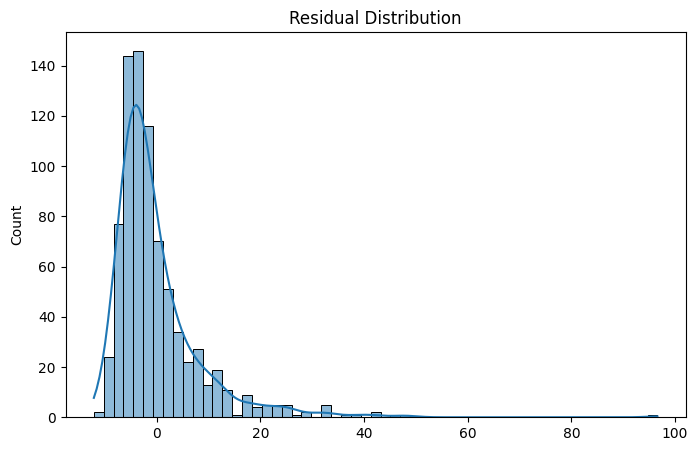

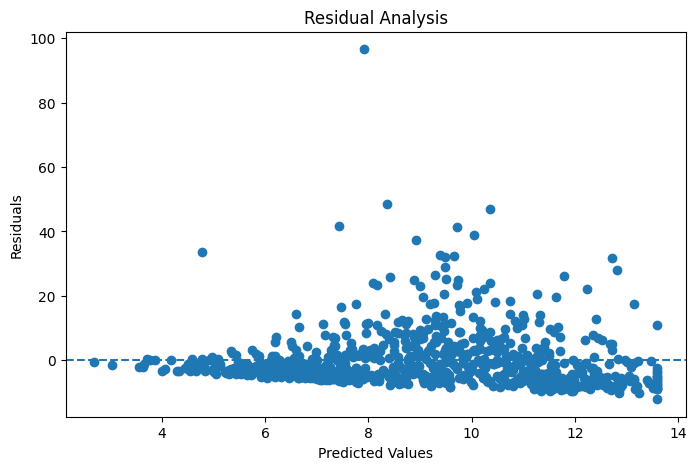

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

residuals = y - predicted_y

plt.figure(figsize=(8,5))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

plt.figure(figsize=(8,5))
plt.scatter(predicted_y, residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

Log-log regression:
\[
\log(Y)=b_0+b_1\log(X)
\]

In [ ]:
valid = (x > 0) & (y > 0)

log_x = np.log(x[valid])
log_y = np.log(y[valid])

log_slope, log_intercept = np.polyfit(
    log_x, log_y, 1
)

print("Log-log slope:", log_slope)
print("Log-log intercept:", log_intercept)

Log-log slope: -0.331607073041092
Log-log intercept: 2.876518505904102


Task 1.7 – Multiple regression using the normal equation
Here you will use multiple independent variables to predict one dependent variable.
\[
\theta=(X^TX)^{-1}X^TY
\]

In [ ]:
# Replace these with actual numerical column names
features = ["customer_tenure_months", "avg_order_value_inr_hundreds"]
target = "order_value_inr_hundreds"

data = df[features + [target]].dropna()

X = data[features].to_numpy()
Y = data[target].to_numpy()

# Add intercept column
X = np.c_[np.ones(X.shape[0]), X]

# Normal equation using pseudo-inverse
theta = np.linalg.pinv(X.T @ X) @ X.T @ Y

print("Regression Coefficients:", theta)

predictions = X @ theta

print("First 5 Predictions:", predictions[:5])

Regression Coefficients: [-1.47246238 -0.05527225  0.64857953]
First 5 Predictions: [ 3.43097744e-01  1.79419042e+01  1.81622977e+01  2.06582467e+01
 -1.77183040e-02]


Save the code in part1.py

In [ ]:
%%writefile /content/drive/MyDrive/flipkart-decision-intelligence/part1.py

import numpy as np
import csv

# Part 1: Statistical Analysis and Regression

import pandas as pd
import numpy as np

df = pd.read_csv("data/records.csv")

print("Dataset loaded successfully")
print(df.head())

from statsmodels.stats.weightstats import ztest

sample = df["customer_tenure_months"].dropna()

population_mean = 100  # Replace with the specified benchmark

z_stat, p_value = ztest(
    sample,
    value=population_mean
)

print("Z Statistic:", z_stat)
print("P Value:", p_value)

if p_value < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")
import math
from scipy.stats import norm

confidence = 0.95
margin_error = 5
sigma = 20

z_value = norm.ppf(1 - (1-confidence)/2)

sample_size = math.ceil(
    (z_value * sigma / margin_error)**2
)

print("Required Sample Size:", sample_size)

x = df["customer_tenure_months"].to_numpy()
y = df["order_value_inr_hundreds"].to_numpy()

slope = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)

intercept = np.mean(y) - slope * np.mean(x)

print("Slope:", slope)
print("Intercept:", intercept)

predicted_y = intercept + slope*x

print("First 5 Predictions:", predicted_y[:5])

x = df["customer_tenure_months"].to_numpy(dtype=float)
y = df["order_value_inr_hundreds"].to_numpy(dtype=float)

# Standardize X for stable gradient descent
x_mean = x.mean()
x_std = x.std()

x_scaled = (x - x_mean) / x_std

m = 0
c = 0

learning_rate = 0.01
n = len(x_scaled)

for i in range(500):

    y_pred = m*x_scaled + c

    dm = (-2/n) * np.sum(x_scaled*(y-y_pred))
    dc = (-2/n) * np.sum(y-y_pred)

    m -= learning_rate * dm
    c -= learning_rate * dc

print("Slope:", m)
print("Intercept:", c)
print("Total Updates: 500")

import matplotlib.pyplot as plt
import seaborn as sns

residuals = y - predicted_y

plt.figure(figsize=(8,5))
sns.histplot(residuals, kde=True)
plt.title("Residual Distribution")
plt.show()

plt.figure(figsize=(8,5))
plt.scatter(predicted_y, residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

# Replace these with actual numerical column names
features = ["customer_tenure_months", "avg_order_value_inr_hundreds"]
target = "order_value_inr_hundreds"

data = df[features + [target]].dropna()

X = data[features].to_numpy()
Y = data[target].to_numpy()

# Add intercept column
X = np.c_[np.ones(X.shape[0]), X]

# Normal equation using pseudo-inverse
theta = np.linalg.pinv(X.T @ X) @ X.T @ Y

print("Regression Coefficients:", theta)

predictions = X @ theta

print("First 5 Predictions:", predictions[:5])

Overwriting /content/drive/MyDrive/flipkart-decision-intelligence/part1.py


Dataset loaded successfully
  record_id  customer_tenure_months  complaint_count_90d  \
0     E0001                    62.2                    1   
1     E0002                    21.9                    6   
2     E0003                    27.3                    7   
3     E0004                    32.6                    7   
4     E0005                    52.3                    3   

   discount_order_share  avg_order_value_inr_hundreds  loyalty_score  \
0                 0.561                           8.1           65.0   
1                 0.425                          31.8           75.8   
2                 0.589                          32.6           54.0   
3                 0.195                          36.9           69.5   
4                 0.345                           6.7           54.2   

   cod_flag  plus_member_flag  churned  order_value_inr_hundreds  
0         0                 0        0                      1.92  
1         0                 0        0      

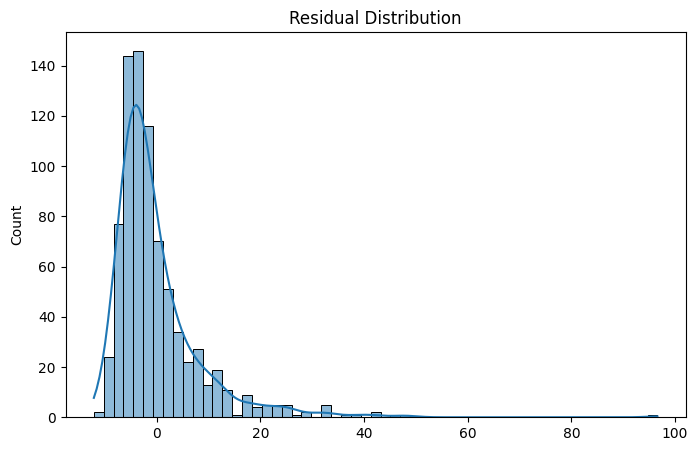

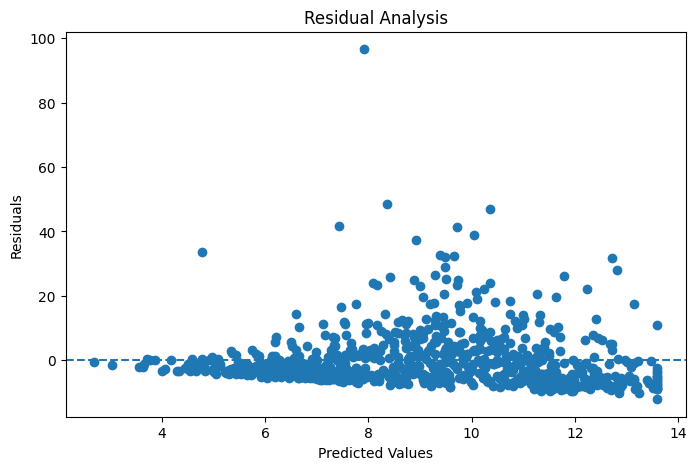

Regression Coefficients: [-1.47246238 -0.05527225  0.64857953]
First 5 Predictions: [ 3.43097744e-01  1.79419042e+01  1.81622977e+01  2.06582467e+01
 -1.77183040e-02]


<Figure size 640x480 with 0 Axes>

In [ ]:
%run /content/drive/MyDrive/flipkart-decision-intelligence/part1.py

**save the results**

In [ ]:
import os

output_path = "outputs/part1_results.txt"

# Create the outputs directory if it doesn't exist
os.makedirs("outputs", exist_ok=True)

with open(output_path, "w") as f:
    f.write("PART 1 RESULTS\n")
    f.write("====================\n")

    # Using the correct variable names 'mean' and 'std' from the active kernel
    f.write(f"Mean value: {mean}\n")
    f.write(f"Standard deviation: {std}\n")

print("Results saved successfully!")

Results saved successfully!


In [ ]:
with open("outputs/part1_results.txt", "w") as f:
    f.write("/content/flipkart-decision-intelligence/outputs/part1_results.txt")

In [ ]:
results_text = f"""PART 1 STATISTICAL ANALYSIS RESULTS
===================================
Mean: {mean:.4f}
Standard Deviation: {std:.4f}
Standard Error: {se:.4f}
95% Confidence Interval: ({ci[0]:.4f}, {ci[1]:.4f})
"""

with open("outputs/part1_results.txt", "w") as f:
    f.write(results_text)

print("Saved successfully!")

Saved successfully!


In [ ]:
import os

files = [
    "part1.py",
    "outputs/part1_results.txt"
]

for file in files:
    print(file, "Exists:", os.path.exists(file))

part1.py Exists: True
outputs/part1_results.txt Exists: True


In [ ]:
with open("outputs/part1_results.txt", "r") as f:
    print(f.read())

PART 1 STATISTICAL ANALYSIS RESULTS
Mean: 32.2494
Standard Deviation: 16.1959
Standard Error: 0.5726
95% Confidence Interval: (31.1254, 33.3734)



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
PROJECT = "/content/drive/MyDrive/flipkart-decision-intelligence"

In [ ]:
with open("outputs/part1_results.txt", "r") as f:
    print(f.read())

PART 1 STATISTICAL ANALYSIS RESULTS
Mean: 32.2494
Standard Deviation: 16.1959
Standard Error: 0.5726
95% Confidence Interval: (31.1254, 33.3734)



In [ ]:
import os

# Verify both paths correctly
print("Drive copy exists:", os.path.exists(f"{PROJECT}/outputs/part1_results.txt"))
print("Local copy exists:", os.path.exists("/content/flipkart-decision-intelligence/outputs/part1_results.txt"))

Drive copy exists: True
Local copy exists: True


In [ ]:
from google.colab import files

files.download(f"{PROJECT}/part1.py")
files.download(f"{PROJECT}/outputs/part1_results.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile part1.py
# Part 1: Statistical Analysis and Regression
import os
import numpy as np
import pandas as pd
import math
from scipy import stats
from scipy.stats import norm
from statsmodels.stats.weightstats import ztest

# Load dataset
df = pd.read_csv("data/records.csv")

# Task 1.1
x = df["customer_tenure_months"].dropna()
mean = np.mean(x)
std = np.std(x, ddof=1)
se = stats.sem(x)
ci = stats.t.interval(0.95, df=len(x)-1, loc=mean, scale=se)

# Task 1.2
population_mean = 100
z_stat, p_value = ztest(x, value=population_mean)

# Task 1.3
confidence = 0.95
margin_error = 5
sigma = 20
z_value = norm.ppf(1 - (1-confidence)/2)
sample_size = math.ceil((z_value * sigma / margin_error)**2)

# Task 1.4
y = df["order_value_inr_hundreds"].to_numpy()
x_np = x.to_numpy()
slope = np.cov(x_np, y, ddof=1)[0, 1] / np.var(x_np, ddof=1)
intercept = np.mean(y) - slope * np.mean(x_np)

# Task 1.7
features = ["customer_tenure_months", "avg_order_value_inr_hundreds"]
target = "order_value_inr_hundreds"
data = df[features + [target]].dropna()
X_mult = data[features].to_numpy()
Y_mult = data[target].to_numpy()
X_mult = np.c_[np.ones(X_mult.shape[0]), X_mult]
theta = np.linalg.pinv(X_mult.T @ X_mult) @ X_mult.T @ Y_mult

# Ensure output directory exists
os.makedirs("outputs", exist_ok=True)

# Save outputs
results_text = f"""PART 1 STATISTICAL ANALYSIS RESULTS
===================================
Mean: {mean:.4f}
Standard Deviation: {std:.4f}
Standard Error: {se:.4f}
95% Confidence Interval: ({ci[0]:.4f}, {ci[1]:.4f})
Z-Statistic: {z_stat:.4f}
p-value: {p_value:.4f}
Required Sample Size: {sample_size}
Simple Linear Regression Slope: {slope:.4f}
Simple Linear Regression Intercept: {intercept:.4f}
Multiple Regression Coefficients (b0, b1, b2): {theta.tolist()}
"""

with open("outputs/part1_results.txt", "w") as f:
    f.write(results_text)

print("Code successfully written and ran! Results saved.")

Overwriting part1.py


In [ ]:
# Execute the script to generate fresh outputs
!python part1.py

Code successfully written and ran! Results saved.


In [ ]:
from google.colab import files
import time

# Trigger downloads to your local machine
print("Downloading part1.py...")
files.download("part1.py")

time.sleep(2) # Brief sleep to handle parallel browser download threads

print("Downloading part1_results.txt...")
files.download("outputs/part1_results.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print("Current directory:", os.getcwd())
print("Files available:", os.listdir())

Current directory: /content
Files available: ['.config', 'sample_data']


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving records.csv to records.csv


# **Part 2: Classification (Complete Step-by-Step Solution)**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("records.csv")

# Select seven independent variables
features = [
    "customer_tenure_months",
    "complaint_count_90d",
    "discount_order_share",
    "avg_order_value_inr_hundreds",
    "loyalty_score",
    "cod_flag",
    "plus_member_flag"
]

X = df[features].to_numpy(dtype=float)
y = df["churned"].to_numpy(dtype=int)

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Positive cases:", np.sum(y == 1))
print("Negative cases:", np.sum(y == 0))

Dataset shape: (800, 7)
Target shape: (800,)
Positive cases: 170
Negative cases: 630


In [ ]:
%%writefile /content/part2.py

Writing /content/part2.py


Stratified 70/30 train-test split
70% training data = 560 records.
30% testing data = 240 records.

In [ ]:
def stratified_split(X, y, test_size=0.30, seed=42):

    rng = np.random.default_rng(seed)

    train_indices = []
    test_indices = []

    for class_value in np.unique(y):

        indices = np.where(y == class_value)[0]

        rng.shuffle(indices)

        n_test = int(round(len(indices) * test_size))

        test_indices.extend(indices[:n_test])
        train_indices.extend(indices[n_test:])

    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)

    rng.shuffle(train_indices)
    rng.shuffle(test_indices)

    return (
        X[train_indices],
        X[test_indices],
        y[train_indices],
        y[test_indices]
    )


X_train, X_test, y_train, y_test = stratified_split(X, y)

print("Training rows:", len(X_train))
print("Training positives:", np.sum(y_train == 1))

print("Testing rows:", len(X_test))
print("Testing positives:", np.sum(y_test == 1))

Training rows: 560
Training positives: 119
Testing rows: 240
Testing positives: 51


Standardise X1–X7

Standardisation is important because your features have different numerical ranges.

Formula:
\[
Z=\frac{X-\mu}{s}
\]

Where:
- \(X\) = original feature value
- \(\mu\) = training mean
- \(s\) = training sample standard deviation

In [ ]:
mean = np.mean(X_train, axis=0)

std = np.std(X_train, axis=0, ddof=1)

X_train_scaled = (X_train - mean) / std

X_test_scaled = (X_test - mean) / std

print("Training means:", mean)
print("Training SD:", std)

print("Scaled training mean:",
      np.mean(X_train_scaled, axis=0))

print("Scaled training SD:",
      np.std(X_train_scaled, axis=0, ddof=1))

Training means: [32.08660714  3.89285714  0.42618214 18.88625    53.62892857  0.42142857
  0.48928571]
Training SD: [16.33071612  2.32800921  0.23034633  9.79378469 13.67633079  0.49422941
  0.50033212]
Scaled training mean: [ 1.58999797e-16 -5.23390854e-17 -1.60982339e-16  7.06181145e-16
 -3.29914667e-15 -1.18952467e-18  5.27355937e-17]
Scaled training SD: [1. 1. 1. 1. 1. 1. 1.]


Implement sigmoid function
Logistic Regression predicts a probability between 0 and 1.
The sigmoid formula is:
\[
\sigma(z)=\frac{1}{1+e^{-z}}
\]

In [ ]:
def sigmoid(z):

    z = np.clip(z, -500, 500)

    return 1 / (1 + np.exp(-z))

In [ ]:
print(sigmoid(0))
print(sigmoid(2))
print(sigmoid(-2))

0.5
0.8807970779778823
0.11920292202211755


Implement Binary Cross-Entropy loss

Binary Cross-Entropy measures how far the model's predicted probabilities are from the actual answers.
\[
L=-\frac{1}{n}\sum_{i=1}^{n}
[y_i\log(p_i)+(1-y_i)\log(1-p_i)]
\]

In [ ]:
def binary_cross_entropy(y_true, probabilities):

    eps = 1e-15

    probabilities = np.clip(
        probabilities, eps, 1 - eps
    )

    loss = -np.mean(
        y_true * np.log(probabilities)
        +
        (1 - y_true) * np.log(1 - probabilities)
    )

    return loss

In [ ]:
initial_probabilities = np.full(len(y_train), 0.5)

initial_loss = binary_cross_entropy(
    y_train,
    initial_probabilities
)

print("Initial loss:", initial_loss)

Initial loss: 0.6931471805599454


This is because the model initially predicts 50% probability for every customer.

Implement Logistic Regression from scratch
We will implement:
- Model weights
- Bias
- Prediction probabilities
- Gradient calculation
- Gradient descent
- 1,000 updates
- Loss tracking

The logistic regression model is:

\[
p=\sigma(Xw+b)
\]
Gradient descent updates the parameters to minimise the loss.

In [ ]:
def train_logistic_regression(
    X,
    y,
    learning_rate=0.1,
    iterations=1000
):

    n_samples, n_features = X.shape

    # Initialise weights and bias
    weights = np.zeros(n_features)
    bias = 0.0

    losses = []

    for iteration in range(iterations):

        # Forward propagation
        z = np.dot(X, weights) + bias

        probabilities = sigmoid(z)

        # Calculate loss
        loss = binary_cross_entropy(
            y, probabilities
        )

        losses.append(loss)

        # Calculate gradients
        dw = np.dot(
            X.T, (probabilities - y)
        ) / n_samples

        db = np.mean(probabilities - y)

        # Gradient descent
        weights -= learning_rate * dw

        bias -= learning_rate * db

    return weights, bias, losses

Train model first

In [ ]:
weights, bias, losses = train_logistic_regression(
    X_train_scaled,
    y_train,
    learning_rate=0.1,
    iterations=1000
)

print("Final weights:", weights)
print("Final bias:", bias)
print("Final loss:", losses[-1])

Final weights: [-0.46742605  0.62894448  0.84947254 -0.01545084 -0.3237313   0.37742613
 -0.23568605]
Final bias: -2.173474680205142
Final loss: 0.3611046449977835


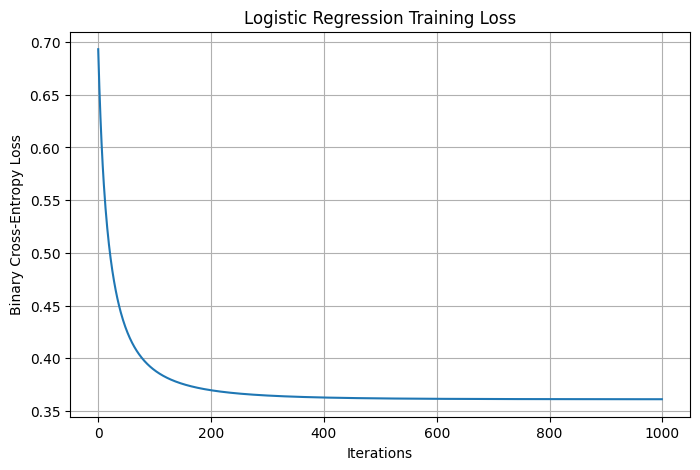

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(losses)

plt.xlabel("Iterations")
plt.ylabel("Binary Cross-Entropy Loss")

plt.title("Logistic Regression Training Loss")

plt.grid()

plt.savefig("part2_loss_curve.png")

plt.show()

Experiment with three learning rates
assignment requires:
0.01
0.1
1.0
will compare their final losses.

In [ ]:
learning_rates = [0.01, 0.1, 1.0]

lr_results = []

for lr in learning_rates:

    w, b, loss_history = train_logistic_regression(
        X_train_scaled,
        y_train,
        learning_rate=lr,
        iterations=1000
    )

    lr_results.append({
        "Learning Rate": lr,
        "Initial Loss": loss_history[0],
        "Final Loss": loss_history[-1]
    })

lr_df = pd.DataFrame(lr_results)

print(lr_df)

   Learning Rate  Initial Loss  Final Loss
0           0.01      0.693147    0.388915
1           0.10      0.693147    0.361105
2           1.00      0.693147    0.361068


In [ ]:
lr_df.to_csv(
    "part2_learning_rates.csv",
    index=False
)

Learning rate	       What to observe
0.01	               Slower learning
0.1	                 Balanced learning
1.0	                 Faster updates; check stability

Do not automatically assume 0.1 is best. Compare the actual final losses.

Calculate odds ratios
An odds ratio tells us how a one-unit increase in a standardised feature changes the odds of churn, holding the other features constant.
\[
OR=e^{\beta}
\]

In [ ]:
odds_ratios = np.exp(weights)

odds_df = pd.DataFrame({
    "Feature": features,
    "Weight": weights,
    "Odds_Ratio": odds_ratios
})

print(odds_df)

                        Feature    Weight  Odds_Ratio
0        customer_tenure_months -0.467426    0.626613
1           complaint_count_90d  0.628944    1.875630
2          discount_order_share  0.849473    2.338413
3  avg_order_value_inr_hundreds -0.015451    0.984668
4                 loyalty_score -0.323731    0.723445
5                      cod_flag  0.377426    1.458526
6              plus_member_flag -0.235686    0.790029


Interpretation:
- OR greater than 1: higher odds of churn.
- OR less than 1: lower odds of churn.
- OR equal to 1: no change in odds.

these odds ratios refer to a one-standard-deviation increase in each feature because the inputs were standardised.

Generate predictions
Now use the trained model to predict churn probabilities on test data.

In [ ]:
test_probabilities = sigmoid(
    np.dot(X_test_scaled, weights) + bias
)

print(test_probabilities[:10])

[0.0128918  0.34729977 0.53912604 0.06242559 0.00645831 0.13306586
 0.04799909 0.22703689 0.04062318 0.00758171]


We will test two thresholds:
- 0.5
- 0.3
A probability above or equal to the threshold is classified as churn.

Calculate TP, FP, TN and FN
These four values are essential.
Term	  Meaning
TP	    Correctly predicted churn
FP	    Predicted churn, but customer did not churn
TN	    Correctly predicted non-churn
FN	    Predicted non-churn, but customer churned

In [ ]:
def confusion_counts(y_true, y_pred):

    TP = np.sum((y_true == 1) & (y_pred == 1))

    FP = np.sum((y_true == 0) & (y_pred == 1))

    TN = np.sum((y_true == 0) & (y_pred == 0))

    FN = np.sum((y_true == 1) & (y_pred == 0))

    return TP, FP, TN, FN

Calculate all evaluation metrics
\[
Accuracy=\frac{TP+TN}{TP+FP+TN+FN}
\]

\[
Precision=\frac{TP}{TP+FP}
\]

\[
Recall=\frac{TP}{TP+FN}
\]

\[
F1=\frac{2PR}{P+R}
\]

\[
Specificity=\frac{TN}{TN+FP}
\]

In [ ]:
def calculate_metrics(y_true, y_pred):

    TP, FP, TN, FN = confusion_counts(
        y_true, y_pred
    )

    accuracy = (TP + TN) / len(y_true)

    precision = TP / (TP + FP) if TP + FP else 0

    recall = TP / (TP + FN) if TP + FN else 0

    specificity = TN / (TN + FP) if TN + FP else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "TP": TP,
        "FP": FP,
        "TN": TN,
        "FN": FN,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Specificity": specificity
    }

Test both threshold

In [ ]:
threshold_results = []

for threshold in [0.5, 0.3]:

    predictions = (
        test_probabilities >= threshold
    ).astype(int)

    metrics = calculate_metrics(
        y_test, predictions
    )

    metrics["Threshold"] = threshold

    threshold_results.append(metrics)

threshold_df = pd.DataFrame(
    threshold_results
)

print(threshold_df)

   TP  FP   TN  FN  Accuracy  Precision    Recall        F1  Specificity  \
0  19  13  176  32  0.812500   0.593750  0.372549  0.457831     0.931217   
1  36  46  143  15  0.745833   0.439024  0.705882  0.541353     0.756614   

   Threshold  
0        0.5  
1        0.3  


In [ ]:
threshold_df.to_csv(
    "part2_thresholds.csv",
    index=False
)

Business interpretation: Lowering the threshold from 0.5 to 0.3 generally identifies more potential churners. It can increase recall but may also increase false positives.

Implement KNN from scratch
Now we move to the second classification model: K-Nearest Neighbours.
KNN works by finding the nearest customers based on their feature values and predicting the majority class among those neighbours.
Distance formula (Euclidean distance):
\[
d(x,y)=\sqrt{\sum_{j=1}^{7}(x_j-y_j)^2}
\]

In [ ]:
def knn_predict(X_train, y_train, X_test, k):

    predictions = []

    for test_point in X_test:

        # Calculate distances
        distances = np.sqrt(
            np.sum((X_train - test_point) ** 2, axis=1)
        )

        # Find nearest k neighbours
        nearest_indices = np.argsort(distances)[:k]

        # Get their labels
        nearest_labels = y_train[nearest_indices]

        # Majority voting
        prediction = int(
            np.sum(nearest_labels) > k / 2
        )

        predictions.append(prediction)

    return np.array(predictions)

In [ ]:
knn_predictions = knn_predict(
    X_train_scaled,
    y_train,
    X_test_scaled,
    k=5
)

print(knn_predictions[:20])

[0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0]


Implement 5-fold cross-validation
assignment requires testing:
\[
K=1,3,5,7,9,11,13,15,17,19,21
\]
We will divide training data into five folds.
Four folds for training.
One fold for validation.
Repeat five times.
Calculate F1 for each fold.
Calculate the average F1.
We must not use the test dataset to choose K.

In [ ]:
def make_stratified_folds(y, n_folds=5, seed=42):

    rng = np.random.default_rng(seed)

    folds = [[] for _ in range(n_folds)]

    for class_value in np.unique(y):

        indices = np.where(y == class_value)[0]

        rng.shuffle(indices)

        for i, index in enumerate(indices):

            folds[i % n_folds].append(index)

    return [
        np.array(fold, dtype=int)
        for fold in folds
    ]

Now implement cross-validation:

In [ ]:
def cross_validate_knn(X, y, k_values):

    folds = make_stratified_folds(
        y, n_folds=5
    )

    results = []

    for k in k_values:

        fold_f1_scores = []

        for i in range(5):

            validation_indices = folds[i]

            training_indices = np.concatenate([
                folds[j]
                for j in range(5)
                if j != i
            ])

            X_fold_train = X[training_indices]
            y_fold_train = y[training_indices]

            X_fold_val = X[validation_indices]
            y_fold_val = y[validation_indices]

            predictions = knn_predict(
                X_fold_train,
                y_fold_train,
                X_fold_val,
                k
            )

            metrics = calculate_metrics(
                y_fold_val,
                predictions
            )

            fold_f1_scores.append(
                metrics["F1"]
            )

        results.append({
            "K": k,
            "Mean_F1": np.mean(fold_f1_scores),
            "Std_F1": np.std(fold_f1_scores)
        })

    return pd.DataFrame(results)

In [ ]:
k_values = list(range(1, 22, 2))

knn_results = cross_validate_knn(
    X_train_scaled,
    y_train,
    k_values
)

print(knn_results)

     K   Mean_F1    Std_F1
0    1  0.371991  0.068480
1    3  0.466482  0.124357
2    5  0.463206  0.099218
3    7  0.494418  0.118797
4    9  0.407525  0.103157
5   11  0.402518  0.093030
6   13  0.418990  0.102226
7   15  0.451156  0.109405
8   17  0.366207  0.146153
9   19  0.379400  0.108884
10  21  0.384490  0.131718


Find the best K

In [ ]:
best_k = int(
    knn_results.loc[
        knn_results["Mean_F1"].idxmax(),
        "K"
    ]
)

print("Best K:", best_k)

print("Best Mean F1:",
      knn_results["Mean_F1"].max())

Best K: 7
Best Mean F1: 0.49441848828845736


Plot the result

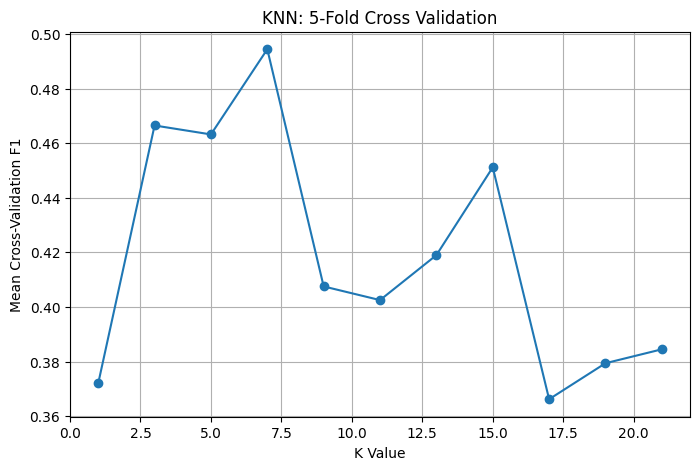

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    knn_results["K"],
    knn_results["Mean_F1"],
    marker="o"
)

plt.xlabel("K Value")
plt.ylabel("Mean Cross-Validation F1")

plt.title("KNN: 5-Fold Cross Validation")

plt.grid()

plt.savefig("part2_knn_cv.png")

plt.show()

Calculate financial cost
\[
Cost=50(FP)+400(FN)
\]
Every false positive costs ₹50.
Every false negative costs ₹400.
A false negative is much more expensive because we fail to identify a customer who actually churns.

In [ ]:
def financial_cost(FP, FN):

    return 50 * FP + 400 * FN

Calculate costs at both thresholds:

In [ ]:
for threshold in [0.5, 0.3]:

    predictions = (
        test_probabilities >= threshold
    ).astype(int)

    TP, FP, TN, FN = confusion_counts(
        y_test, predictions
    )

    cost = financial_cost(FP, FN)

    print("\nThreshold:", threshold)

    print("False Positives:", FP)

    print("False Negatives:", FN)

    print("Financial Cost: ₹", cost)


Threshold: 0.5
False Positives: 13
False Negatives: 32
Financial Cost: ₹ 13450

Threshold: 0.3
False Positives: 46
False Negatives: 15
Financial Cost: ₹ 8300


Find the best threshold using training data only
Do not use test labels to select your threshold.
We will generate out-of-fold predictions on training data and use these to compare thresholds based on financial cost.

In [ ]:
def get_oof_logistic_probabilities(
    X,
    y,
    learning_rate=0.1,
    iterations=1000
):

    folds = make_stratified_folds(
        y, n_folds=5
    )

    oof_probabilities = np.zeros(len(y))

    for i in range(5):

        val_idx = folds[i]

        train_idx = np.concatenate([
            folds[j]
            for j in range(5)
            if j != i
        ])

        w, b, _ = train_logistic_regression(
            X[train_idx],
            y[train_idx],
            learning_rate,
            iterations
        )

        oof_probabilities[val_idx] = sigmoid(
            np.dot(X[val_idx], w) + b
        )

    return oof_probabilities

In [ ]:
oof_probabilities = get_oof_logistic_probabilities(
    X_train_scaled,
    y_train
)

threshold_candidates = np.arange(
    0.05, 0.96, 0.01
)

cost_results = []

for threshold in threshold_candidates:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    TP, FP, TN, FN = confusion_counts(
        y_train, predictions
    )

    cost = financial_cost(FP, FN)

    cost_results.append({
        "Threshold": threshold,
        "TP": TP,
        "FP": FP,
        "TN": TN,
        "FN": FN,
        "Cost": cost
    })

cost_df = pd.DataFrame(cost_results)

best_row = cost_df.loc[
    cost_df["Cost"].idxmin()
]

best_threshold = best_row["Threshold"]

print("Best threshold:", best_threshold)

print("Minimum training CV cost:", best_row["Cost"])

Best threshold: 0.09000000000000001
Minimum training CV cost: 12150.0


We have now selected a threshold without looking at test outcomes.

Evaluate the final logistic regression model at this threshold:

In [ ]:
final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

final_metrics = calculate_metrics(
    y_test,
    final_predictions
)

final_cost = financial_cost(
    final_metrics["FP"],
    final_metrics["FN"]
)

print("Final test metrics:", final_metrics)

print("Final test financial cost:", final_cost)

Final test metrics: {'TP': np.int64(47), 'FP': np.int64(94), 'TN': np.int64(95), 'FN': np.int64(4), 'Accuracy': np.float64(0.5916666666666667), 'Precision': np.float64(0.3333333333333333), 'Recall': np.float64(0.9215686274509803), 'F1': np.float64(0.48958333333333326), 'Specificity': np.float64(0.5026455026455027)}
Final test financial cost: 6300


Evaluate the best KNN model
Now use your selected K on the test set.

In [ ]:
best_knn_predictions = knn_predict(
    X_train_scaled,
    y_train,
    X_test_scaled,
    best_k
)

best_knn_metrics = calculate_metrics(
    y_test,
    best_knn_predictions
)

print("Best K:", best_k)

print("KNN test metrics:")

for metric, value in best_knn_metrics.items():

    print(metric, ":", value)

Best K: 7
KNN test metrics:
TP : 14
FP : 26
TN : 163
FN : 37
Accuracy : 0.7375
Precision : 0.35
Recall : 0.27450980392156865
F1 : 0.3076923076923077
Specificity : 0.8624338624338624


For the financial cost:

In [ ]:
knn_cost = financial_cost(
    best_knn_metrics["FP"],
    best_knn_metrics["FN"]
)

print("KNN financial cost: ₹", knn_cost)

KNN financial cost: ₹ 16100


In [ ]:
# 1. Save logistic regression losses

pd.DataFrame({
    "Iteration": np.arange(1, len(losses) + 1),
    "Loss": losses
}).to_csv(
    "part2_losses.csv",
    index=False
)


# 2. Save weights and odds ratios

weights_df = pd.DataFrame({
    "Feature": features,
    "Weight": weights,
    "Odds_Ratio": np.exp(weights)
})

weights_df.to_csv(
    "part2_weights.csv",
    index=False
)


# 3. Save threshold evaluation and financial costs

final_threshold_rows = []

for threshold in [0.5, 0.3, best_threshold]:

    predictions = (
        test_probabilities >= threshold
    ).astype(int)

    metrics = calculate_metrics(
        y_test, predictions
    )

    metrics["Threshold"] = threshold

    metrics["Financial_Cost"] = financial_cost(
        metrics["FP"],
        metrics["FN"]
    )

    metrics["Model"] = "Logistic Regression"

    final_threshold_rows.append(metrics)


knn_row = best_knn_metrics.copy()

knn_row["Threshold"] = np.nan

knn_row["Financial_Cost"] = knn_cost

knn_row["Model"] = f"KNN (K={best_k})"

final_threshold_rows.append(knn_row)

pd.DataFrame(
    final_threshold_rows
).to_csv(
    "part2_thresholds.csv",
    index=False
)

print("All three Part 2 files saved successfully!")

All three Part 2 files saved successfully!


save the KNN cross-validation table separately

In [ ]:
knn_results.to_csv(
    "part2_knn_cv.csv",
    index=False
)

In [ ]:
%run part2.py

Exception: File `'part2.py'` not found.

In [ ]:
import os

project_folder = "/content/drive/MyDrive/flipkart-decision-intelligence"

print("Files in your project folder:")
print(os.listdir(project_folder))

print("\nSearching for Part 2 CSV files:")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.startswith("part2_") and file.endswith(".csv"):
            print(os.path.join(root, file))

Files in your project folder:
['data', 'outputs', 'README.md', 'utils.py', 'part3.py', 'part4.py', 'requirements.txt', 'generate_data.py', 'part1.py', 'part2_losses.csv', 'part2_weights.csv', 'part2_thresholds.csv', 'part2_knn_cv.csv', 'part2.py', 'records.csv']

Searching for Part 2 CSV files:
/content/part2_knn_cv.csv
/content/part2_losses.csv
/content/part2_learning_rates.csv
/content/part2_weights.csv
/content/part2_thresholds.csv
/content/drive/MyDrive/flipkart-decision-intelligence/part2_losses.csv
/content/drive/MyDrive/flipkart-decision-intelligence/part2_weights.csv
/content/drive/MyDrive/flipkart-decision-intelligence/part2_thresholds.csv
/content/drive/MyDrive/flipkart-decision-intelligence/part2_knn_cv.csv


In [ ]:
import os
import shutil

project_folder = "/content/drive/MyDrive/flipkart-decision-intelligence"

csv_files = [
    "part2_losses.csv",
    "part2_weights.csv",
    "part2_thresholds.csv",
    "part2_knn_cv.csv"
]

for file in csv_files:
    source = "/content/" + file
    destination = os.path.join(project_folder, file)

    if os.path.exists(source):
        shutil.copy(source, destination)
        print("Copied:", file)
    else:
        print("Not found in /content:", file)

Copied: part2_losses.csv
Copied: part2_weights.csv
Copied: part2_thresholds.csv
Copied: part2_knn_cv.csv


In [ ]:
import os

project_folder = "/content/drive/MyDrive/flipkart-decision-intelligence"

print("Part 2 file exists:",
      os.path.exists(os.path.join(project_folder, "part2.py")))

print("Git repository exists:",
      os.path.exists(os.path.join(project_folder, ".git")))

Part 2 file exists: True
Git repository exists: False


In [ ]:
!git add part2.py
!git commit -m "Add Part 2 classification implementation"
!git push

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [ ]:
import os

project_folder = "/content/drive/MyDrive/flipkart-decision-intelligence"

print(os.listdir(project_folder))

['data', 'outputs', 'README.md', 'utils.py', 'part3.py', 'part4.py', 'requirements.txt', 'generate_data.py', 'part1.py', 'part2_losses.csv', 'part2_weights.csv', 'part2_thresholds.csv', 'part2_knn_cv.csv', 'part2.py', 'records.csv']


In [ ]:
threshold_df.to_csv("part2_thresholds.csv", index=False)

In [ ]:
"""
Part 3 — Segmentation and dimensionality reduction
Uses all 800 rows and X1-X5 from the Flipkart records dataset.

Expected columns:
X1 customer_tenure_months
X2 complaint_count_90d
X3 discount_order_share
X4 avg_order_value_inr_hundreds
X5 loyalty_score
outcome: churned
value: order_value_inr_hundreds
"""

from pathlib import Path
import numpy as np
import pandas as pd

BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Locate the dataset. Expanded search path candidates to find records.csv
candidates = [
    Path("/content/records.csv"),
    Path("/content/drive/MyDrive/flipkart-decision-intelligence/data/records.csv"),
    BASE_DIR / "records.csv",
    BASE_DIR / "data" / "records.csv",
    BASE_DIR / "flipkart-decision-intelligence" / "data" / "records.csv",
    BASE_DIR / "records(2).csv",
    BASE_DIR / "records (2).csv",
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    csv_candidates = [
        p for p in BASE_DIR.glob("**/*.csv")
        if p.name not in {
            "part3_segments.csv", "part3_hierarchical.csv",
            "part2_losses.csv", "part2_weights.csv",
            "part2_thresholds.csv", "part2_knn_cv.csv"
        } and "sample_data" not in p.parts
    ]
    if len(csv_candidates) >= 1:
        DATA_PATH = csv_candidates[0]
    else:
        raise FileNotFoundError(
            "Could not identify the dataset. Put records.csv (or records(2).csv) "
            "in the same folder or data/ folder as part3.py."
        )

df = pd.read_csv(DATA_PATH)
if len(df) != 800:
    raise ValueError(f"Expected 800 rows, found {len(df)}.")

feature_cols = [
    "customer_tenure_months",
    "complaint_count_90d",
    "discount_order_share",
    "avg_order_value_inr_hundreds",
    "loyalty_score",
]
outcome_col = "churned"
value_col = "order_value_inr_hundreds"
required = feature_cols + [outcome_col, value_col]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required dataset columns: {missing}")

raw = df[feature_cols].to_numpy(dtype=float)
n, p = raw.shape

# ---------------------------------------------------------------------
# 3.1 Standardisation and K-means from scratch
# ---------------------------------------------------------------------
means = raw.mean(axis=0)
sample_sds = raw.std(axis=0, ddof=1)
if np.any(sample_sds == 0):
    raise ValueError("At least one predictor has zero sample standard deviation.")
X = (raw - means) / sample_sds

def kmeans_pinned(data, k):
    """Pinned initial rows, squared Euclidean distance, no iteration cap."""
    step = len(data) // k
    initial_indices = [j * step for j in range(k)]
    centroids = data[initial_indices].copy()
    labels = np.full(len(data), -1, dtype=int)
    passes = 0

    while True:
        # argmin returns the first (lowest-numbered) centroid on ties.
        squared_distances = ((data[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        new_labels = np.argmin(squared_distances, axis=1)
        passes += 1
        unchanged = np.array_equal(new_labels, labels)
        labels = new_labels

        new_centroids = centroids.copy()
        for cluster_id in range(k):
            members = data[labels == cluster_id]
            if len(members) > 0:
                new_centroids[cluster_id] = members.mean(axis=0)
        centroids = new_centroids

        if unchanged:
            break

    # WCSS measured from each row to its final cluster centroid.
    residuals = data - centroids[labels]
    wcss = float(np.sum(residuals ** 2))
    return labels, centroids, wcss, passes

kmeans_results = {}
for k in range(2, 7):
    labels, centers, wcss, passes = kmeans_pinned(X, k)
    kmeans_results[k] = {
        "labels": labels, "centers": centers,
        "wcss": wcss, "passes": passes
    }

wcss = {k: kmeans_results[k]["wcss"] for k in range(2, 7)}
elbow_k = None
for k in (3, 4, 5):
    if (wcss[k] - wcss[k + 1]) < 0.5 * (wcss[k - 1] - wcss[k]):
        elbow_k = k
        break
# ---------------------------------------------------------------------
# 3.3 Profile K=3 segments, ordered by ascending original-unit mean X3
# ---------------------------------------------------------------------
labels3 = kmeans_results[3]["labels"]
cluster_ids = sorted(
    range(3),
    key=lambda cid: raw[labels3 == cid, 2].mean()
)
segment_labels = np.empty(n, dtype=object)
segment_rows = []
segment_indices = {}

for name, cid in zip(("A", "B", "C"), cluster_ids):
    mask = labels3 == cid
    segment_labels[mask] = name
    segment_indices[name] = mask
    segment_rows.append({
        "segment": name,
        "size": int(mask.sum()),
        "mean_X1": float(raw[mask, 0].mean()),
        "mean_X2": float(raw[mask, 1].mean()),
        "mean_X3": float(raw[mask, 2].mean()),
        "mean_X4": float(raw[mask, 3].mean()),
        "mean_X5": float(raw[mask, 4].mean()),
        "outcome_rate": float(df.loc[mask, outcome_col].mean()),
        "mean_value": float(df.loc[mask, value_col].mean()),
    })

segments_df = pd.DataFrame(segment_rows, columns=[
    "segment", "size", "mean_X1", "mean_X2", "mean_X3",
    "mean_X4", "mean_X5", "outcome_rate", "mean_value"
])
segments_df.to_csv(OUTPUT_DIR / "part3_segments.csv", index=False)

# ---------------------------------------------------------------------
# 3.4 Agglomerative hierarchical clustering from supplied distance table
# ---------------------------------------------------------------------
names = ["E1", "E2", "E3", "E4", "E5", "E6"]
D = np.array([
    [0.0, 7.9, 7.4, 2.9, 2.9, 6.1],
    [7.9, 0.0, 1.4, 5.9, 5.3, 2.0],
    [7.4, 1.4, 0.0, 5.8, 4.6, 1.3],
    [2.9, 5.9, 5.8, 0.0, 2.8, 4.5],
    [2.9, 5.3, 4.6, 2.8, 0.0, 3.4],
    [6.1, 2.0, 1.3, 4.5, 3.4, 0.0],
], dtype=float)

def cluster_distance(cluster1, cluster2, method):
    distances = [D[i, j] for i in cluster1 for j in cluster2]
    if method == "single":
        return min(distances)
    if method == "complete":
        return max(distances)
    if method == "average":
        return sum(distances) / len(distances)
    raise ValueError("Unknown linkage method")

def hierarchical(method):
    clusters = [[i] for i in range(len(names))]
    merge_rows = []
    heights = []

    for merge_no in range(1, len(names)):
        best = None
        best_distance = float("inf")
        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                distance = cluster_distance(clusters[i], clusters[j], method)
                if distance < best_distance:
                    best_distance = distance
                    best = (i, j)

        i, j = best
        ca, cb = clusters[i], clusters[j]
        # cluster_a is the one with the smaller minimum member index.
        if min(ca) > min(cb):
            ca, cb = cb, ca

        def format_cluster(c):
            return "+".join(names[idx] for idx in sorted(c))
        merge_rows.append({
            "linkage": method,
            "merge_no": merge_no,
            "cluster_a": format_cluster(ca),
            "cluster_b": format_cluster(cb),
            "height": float(best_distance),
        })
        heights.append(float(best_distance))

        merged = sorted(ca + cb)
        # Remove original indices safely, then add merged cluster.
        for idx in sorted((i, j), reverse=True):
            clusters.pop(idx)
        clusters.append(merged)
        clusters.sort(key=lambda c: min(c))

    gaps = np.diff(heights)
    largest_gap_index = int(np.argmax(gaps))
    merges_below_cut = largest_gap_index + 1
    clusters_at_cut = 6 - merges_below_cut

    return merge_rows, heights, clusters_at_cut

hierarchical_rows = []
cut_counts = {}
for method in ("single", "complete", "average"):
    rows, heights, count = hierarchical(method)
    hierarchical_rows.extend(rows)
    cut_counts[method] = count

hierarchical_df = pd.DataFrame(hierarchical_rows, columns=[
    "linkage", "merge_no", "cluster_a", "cluster_b", "height"
])
hierarchical_df.to_csv(OUTPUT_DIR / "part3_hierarchical.csv", index=False)

# Recover actual cluster memberships at the cut for reporting.
def clusters_at_largest_gap(method):
    clusters = [[i] for i in range(6)]
    rows, heights, _ = hierarchical(method)
    gaps = np.diff(heights)
    merges_to_apply = int(np.argmax(gaps)) + 1
    for row in rows[:merges_to_apply]:
        a = [names.index(x) for x in row["cluster_a"].split("+")]
        b = [names.index(x) for x in row["cluster_b"].split("+")]
        ca = next(c for c in clusters if sorted(c) == sorted(a))
        cb = next(c for c in clusters if sorted(c) == sorted(b))
        clusters.remove(ca)
        clusters.remove(cb)
        clusters.append(sorted(ca + cb))
        clusters.sort(key=lambda c: min(c))
    return ["+".join(names[i] for i in c) for c in clusters]

cut_memberships = {
    method: clusters_at_largest_gap(method)
    for method in ("single", "complete", "average")
}
# ---------------------------------------------------------------------
# 3.5 PCA by the seven required steps
# ---------------------------------------------------------------------
# Step 1: Standardised mean vector is approximately all zeros.
standardised_mean = X.mean(axis=0)
# Step 2: Centre the standardised data.
X_centered = X - X.mean(axis=0)
# Step 3: Sample covariance matrix.
S = (X_centered.T @ X_centered) / (n - 1)
# Step 4: Eigen-decomposition (the allowed library routine).
eigenvalues, eigenvectors = np.linalg.eigh(S)
# Step 5: Sort eigenvalues descending.
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
# Sign convention: largest-absolute entry in each vector is positive.
for j in range(eigenvectors.shape[1]):
    pivot = np.argmax(np.abs(eigenvectors[:, j]))
    if eigenvectors[pivot, j] < 0:
        eigenvectors[:, j] *= -1
# Step 6: Keep top two eigenvectors.
W = eigenvectors[:, :2]
# Step 7: Project all rows.
Z = X_centered @ W

eigenvalue_sum = float(eigenvalues.sum())
explained = eigenvalues / eigenvalue_sum
cumulative = np.cumsum(explained)
components_for_80pct = int(np.argmax(cumulative >= 0.8) + 1)

# ---------------------------------------------------------------------
# Write every requested key to part3_results.txt
# ---------------------------------------------------------------------
result_lines = []
def add(key, value):
    if isinstance(value, (float, np.floating)):
        result_lines.append(f"{key} = {value:.10f}")
    else:
        result_lines.append(f"{key} = {value}")

for k in range(2, 7):
    add(f"wcss_k{k}", wcss[k])
    add(f"kmeans_passes_k{k}", kmeans_results[k]["passes"])
add("elbow_k", elbow_k if elbow_k is not None else "no qualifying K")

for row in segment_rows:
    name = row["segment"]
    add(f"size_segment_{name}", row["size"])

for method in ("single", "complete", "average"):
    add(f"{method}_clusters_at_cut", "; ".join(cut_memberships[method]))

add("standardised_mean_vector", np.array2string(standardised_mean, precision=10))
add("eigenvalue_sum", eigenvalue_sum)
for i in range(5):
    add(f"eigenvalue_{i+1}", eigenvalues[i])
for i in range(5):
    add(f"explained_ratio_{i+1}", explained[i])
for i in range(5):
    add(f"cumulative_ratio_{i+1}", cumulative[i])
add("components_for_80pct", components_for_80pct)

for j in range(5):
    add(f"pc1_loading_X{j+1}", W[j, 0])
for j in range(5):
    add(f"pc2_loading_X{j+1}", W[j, 1])

for r in range(3):
    add(f"row{r+1}_pc1", Z[r, 0])
    add(f"row{r+1}_pc2", Z[r, 1])

for name in ("A", "B", "C"):
    add(f"mean_pc1_segment_{name}", Z[segment_indices[name], 0].mean())

(OUTPUT_DIR / "part3_results.txt").write_text(
    "\n".join(result_lines) + "\n", encoding="utf-8"
)

# Also print a compact completion summary.
print(f"Dataset: {DATA_PATH}")
print(f"Rows used: {n}")
print(f"X columns: {feature_cols}")
print("\nWCSS:")
for k in range(2, 7):
    print(f"  K={k}: {wcss[k]:.4f} (passes={kmeans_results[k]['passes']})")
print(f"Elbow K: {elbow_k}")
print("\nSegments:")
print(segments_df.to_string(index=False))
print("\nHierarchical clusters at cut:")
for method in ("single", "complete", "average"):
    print(f"  {method}: {cut_memberships[method]}")
print(f"\nPCA eigenvalue sum: {eigenvalue_sum:.4f}")


Dataset: /content/drive/MyDrive/flipkart-decision-intelligence/data/records.csv
Rows used: 800
X columns: ['customer_tenure_months', 'complaint_count_90d', 'discount_order_share', 'avg_order_value_inr_hundreds', 'loyalty_score']

WCSS:
  K=2: 2262.6753 (passes=6)
  K=3: 1602.8471 (passes=7)
  K=4: 1494.7732 (passes=21)
  K=5: 1323.7157 (passes=15)
  K=6: 1278.1691 (passes=27)
Elbow K: 3

Segments:
segment  size   mean_X1  mean_X2  mean_X3   mean_X4   mean_X5  outcome_rate  mean_value
      A   322 47.502795 1.950311 0.224984 12.530124 62.158385      0.018634    3.597609
      B   255 28.607059 6.070588 0.453396 28.719216 55.008235      0.235294   17.124824
      C   223 14.389238 4.228700 0.711843 16.509865 38.521525      0.466368    7.288251

Hierarchical clusters at cut:
  single: ['E1', 'E2+E3+E6', 'E4', 'E5']
  complete: ['E1+E4+E5', 'E2+E3+E6']
  average: ['E1+E4+E5', 'E2+E3+E6']

PCA eigenvalue sum: 5.0000


In [ ]:
import os
import pandas as pd

folder = "/content/flipkart/outputs"

for file in os.listdir(folder):
    if file.endswith(".csv"):
        path = os.path.join(folder, file)
        df = pd.read_csv(path)
        print("\nFile:", file)
        print("Rows and columns:", df.shape)
        print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/flipkart/outputs'

In [ ]:
import os

print("Folders inside /content:")
print(os.listdir("/content"))

Folders inside /content:
['.config', 'part2_knn_cv.csv', 'drive', 'outputs', 'part2_losses.csv', 'part2_learning_rates.csv', 'part2_weights.csv', 'part2_loss_curve.png', 'part2_knn_cv.png', 'part2_thresholds.csv', 'records.csv', 'sample_data']


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/part2_knn_cv.csv
/content/part2_losses.csv
/content/part2_learning_rates.csv
/content/part2_weights.csv
/content/part2_thresholds.csv
/content/records.csv
/content/drive/MyDrive/processed.cleveland.data.csv
/content/drive/MyDrive/flipkart-decision-intelligence/part2_losses.csv
/content/drive/MyDrive/flipkart-decision-intelligence/part2_weights.csv
/content/drive/MyDrive/flipkart-decision-intelligence/part2_thresholds.csv
/content/drive/MyDrive/flipkart-decision-intelligence/part2_knn_cv.csv
/content/drive/MyDrive/flipkart-decision-intelligence/records.csv
/content/drive/MyDrive/flipkart-decision-intelligence/data/records.csv
/content/drive/MyDrive/flipkart-decision-intelligence/outputs/records.csv
/content/drive/MyDrive/flipkart-decision-intelligence/outputs/part3_segments.csv
/content/drive/MyDrive/flipkart-decision-intelligence/outputs/part3_hierarchical.csv
/content/outputs/part3_hierarchical.csv
/content/outputs/part3_segments.csv
/content/outputs/records.csv
/content/samp

In [ ]:
import os
import shutil

project = "/content/drive/MyDrive/flipkart-decision-intelligence"
output_folder = os.path.join(project, "outputs")

os.makedirs(output_folder, exist_ok=True)

part2_files = [
    "part2_knn_cv.csv",
    "part2_losses.csv",
    "part2_learning_rates.csv",
    "part2_weights.csv",
    "part2_thresholds.csv"
]

for file in part2_files:
    source = os.path.join(project, file)
    destination = os.path.join(output_folder, file)

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print("Copied:", file)
    else:
        print("Not found:", file)

Copied: part2_knn_cv.csv
Copied: part2_losses.csv
Not found: part2_learning_rates.csv
Copied: part2_weights.csv
Copied: part2_thresholds.csv


In [ ]:
import pandas as pd
import os

for file in os.listdir(output_folder):
    if file.endswith(".csv"):
        path = os.path.join(output_folder, file)
        df = pd.read_csv(path)

        print("\n", file)
        print("Rows and columns:", df.shape)
        print(df.head(3))


 records.csv
Rows and columns: (800, 10)
  record_id  customer_tenure_months  complaint_count_90d  \
0     E0001                    62.2                    1   
1     E0002                    21.9                    6   
2     E0003                    27.3                    7   

   discount_order_share  avg_order_value_inr_hundreds  loyalty_score  \
0                 0.561                           8.1           65.0   
1                 0.425                          31.8           75.8   
2                 0.589                          32.6           54.0   

   cod_flag  plus_member_flag  churned  order_value_inr_hundreds  
0         0                 0        0                      1.92  
1         0                 0        0                     14.29  
2         0                 1        1                      7.86  

 part3_segments.csv
Rows and columns: (3, 9)
  segment  size    mean_X1   mean_X2   mean_X3    mean_X4    mean_X5  \
0       A   322  47.502795  1.950311  0.22

In [ ]:
%%writefile part4.py
"""Part 4 solution. Run from this folder with: python part4.py"""
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent
OUTPUT = ROOT / "outputs"
OUTPUT.mkdir(exist_ok=True)
DATA = ROOT / "records.csv"

# Seven features to use
FEATURES = [
    "customer_tenure_months",
    "complaint_count_90d",
    "discount_order_share",
    "avg_order_value_inr_hundreds",
    "loyalty_score",
    "cod_flag",
    "plus_member_flag"
]

# --- Copy of helper functions from Part 2 to make script self-contained ---

def stratified_split(X, y, test_size=0.30, seed=42):
    rng = np.random.default_rng(seed)
    train_indices = []
    test_indices = []
    for class_value in np.unique(y):
        indices = np.where(y == class_value)[0]
        rng.shuffle(indices)
        n_test = int(round(len(indices) * test_size))
        test_indices.extend(indices[:n_test])
        train_indices.extend(indices[n_test:])
    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)
    rng.shuffle(train_indices)
    rng.shuffle(test_indices)
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y_true, probabilities):
    eps = 1e-15
    probabilities = np.clip(probabilities, eps, 1 - eps)
    return -np.mean(y_true * np.log(probabilities) + (1 - y_true) * np.log(1 - probabilities))

def train_logistic_regression(X, y, learning_rate=0.1, iterations=1000):
    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    bias = 0.0
    losses = []
    for _ in range(iterations):
        z = np.dot(X, weights) + bias
        probabilities = sigmoid(z)
        loss = binary_cross_entropy(y, probabilities)
        losses.append(loss)
        dw = np.dot(X.T, (probabilities - y)) / n_samples
        db = np.mean(probabilities - y)
        weights -= learning_rate * dw
        bias -= learning_rate * db
    return weights, bias, losses

def knn_predict(X_train, y_train, X_test, k):
    predictions = []
    for test_point in X_test:
        distances = np.sqrt(np.sum((X_train - test_point) ** 2, axis=1))
        nearest_indices = np.argsort(distances)[:k]
        nearest_labels = y_train[nearest_indices]
        prediction = int(np.sum(nearest_labels) > k / 2)
        predictions.append(prediction)
    return np.array(predictions)

def knn_probabilities(X_train, y_train, X_test, k):
    probs = []
    for test_point in X_test:
        distances = np.sqrt(np.sum((X_train - test_point) ** 2, axis=1))
        nearest_indices = np.argsort(distances)[:k]
        nearest_labels = y_train[nearest_indices]
        prob = np.sum(nearest_labels) / k
        probs.append(prob)
    return np.array(probs)

def make_stratified_folds(y, n_folds=5, seed=42):
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(n_folds)]
    for class_value in np.unique(y):
        indices = np.where(y == class_value)[0]
        rng.shuffle(indices)
        for i, index in enumerate(indices):
            folds[i % n_folds].append(index)
    return [np.array(fold, dtype=int) for fold in folds]

def cross_validate_knn(X, y, k_values):
    folds = make_stratified_folds(y, n_folds=5)
    results = []
    for k in k_values:
        fold_f1_scores = []
        for i in range(5):
            validation_indices = folds[i]
            training_indices = np.concatenate([folds[j] for j in range(5) if j != i])
            X_fold_train = X[training_indices]
            y_fold_train = y[training_indices]
            X_fold_val = X[validation_indices]
            y_fold_val = y[validation_indices]
            predictions = knn_predict(X_fold_train, y_fold_train, X_fold_val, k)
            metrics = calculate_metrics(y_fold_val, predictions)
            fold_f1_scores.append(metrics["F1"])
        results.append({"K": k, "Mean_F1": np.mean(fold_f1_scores)})
    return results

def confusion_counts(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return TP, FP, TN, FN

def calculate_metrics(y_true, y_pred):
    TP, FP, TN, FN = confusion_counts(y_true, y_pred)
    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    specificity = TN / (TN + FP) if TN + FP else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    return {
        "TP": TP, "FP": FP, "TN": TN, "FN": FN,
        "Accuracy": accuracy, "Precision": precision,
        "Recall": recall, "F1": f1, "Specificity": specificity
    }

def get_oof_logistic_probabilities(X, y, learning_rate=0.1, iterations=1000):
    folds = make_stratified_folds(y, n_folds=5)
    oof_probabilities = np.zeros(len(y))
    for i in range(5):
        val_idx = folds[i]
        train_idx = np.concatenate([folds[j] for j in range(5) if j != i])
        w, b, _ = train_logistic_regression(X[train_idx], y[train_idx], learning_rate, iterations)
        oof_probabilities[val_idx] = sigmoid(np.dot(X[val_idx], w) + b)
    return oof_probabilities

def financial_cost(FP, FN):
    return 50 * FP + 400 * FN

# --- Part 4 Logic Functions ---

def entropy(labels):
    if len(labels) == 0:
        return 0.0
    p = np.mean(labels)
    terms = [q * np.log2(q) for q in (p, 1-p) if q > 0]
    return float(-sum(terms))

def gini(labels):
    if len(labels) == 0:
        return 0.0
    p = np.mean(labels)
    return float(1 - p**2 - (1-p)**2)

def score_splits(X_train, y_train):
    conditions = {
        "S1": X_train[:, 5] == 1,
        "S2": X_train[:, 6] == 1,
        "S3": X_train[:, 2] > 0.5,
        "S4": X_train[:, 0] <= 24,
    }
    root_h, root_g = entropy(y_train), gini(y_train)
    rows = []
    for name, yes_mask in conditions.items():
        y_yes, y_no = y_train[yes_mask], y_train[~yes_mask]
        weighted_h = (len(y_yes)*entropy(y_yes) + len(y_no)*entropy(y_no))/len(y_train)
        weighted_g = (len(y_yes)*gini(y_yes) + len(y_no)*gini(y_no))/len(y_train)
        rows.append({
            "split": name, "n_yes": len(y_yes), "positives_yes": int(y_yes.sum()),
            "n_no": len(y_no), "positives_no": int(y_no.sum()),
            "info_gain": root_h-weighted_h, "gini_gain": root_g-weighted_g,
        })
    return root_h, root_g, pd.DataFrame(rows), conditions

def run_adaboost():
    y = np.array([1, 1, 1, -1, -1, -1, 1, -1], dtype=int)
    h1 = np.array([1, 1, -1, -1, -1, -1, -1, -1], dtype=int)
    h2 = np.array([-1, 1, 1, -1, 1, -1, 1, -1], dtype=int)
    weights = np.full(8, 1/8, dtype=float)
    rows, errors, alphas = [], [], []
    for round_no, h in ((1, h1), (2, h2)):
        before = weights.copy()
        error = float(before[h != y].sum())
        alpha = float(0.5 * np.log((1-error)/error))
        unnormalised = before * np.exp(-alpha * y * h)
        after = unnormalised / unnormalised.sum()
        errors.append(error)
        alphas.append(alpha)
        for i in range(8):
            rows.append({
                "round": round_no, "point": i+1,
                "weight_before": before[i],
                "weight_unnormalised": unnormalised[i],
                "weight_after": after[i],
            })
        weights = after
    ensemble = np.sign(alphas[0]*h1 + alphas[1]*h2)
    accuracy = float(np.mean(ensemble == y))
    return errors, alphas, pd.DataFrame(rows), accuracy

def architecture():
    mlp = [
        ("mlp_hidden1", 784*16 + 16),
        ("mlp_hidden2", 16*16 + 16),
        ("mlp_output", 16*10 + 10),
    ]
    cnn = [
        ("cnn_conv1", (5*5*1 + 1)*6),
        ("cnn_conv2", (5*5*6 + 1)*16),
        ("cnn_dense1", (5*5*16)*32 + 32),
        ("cnn_dense2", 32*10 + 10),
    ]
    rnn_total = 64*128 + 128*128 + 128*16 + 128 + 16
    fc_params = (128*128*3)*1024 + 1024
    conv_params = (3*3*3 + 1)*64
    rows = mlp + cnn
    return rows, sum(v for _, v in mlp), sum(v for _, v in cnn), fc_params, conv_params, rnn_total

def main():
    df = pd.read_csv(DATA)
    X = df[FEATURES].to_numpy(dtype=float)
    y = df["churned"].to_numpy(dtype=int)
    X_train, X_test, y_train, y_test = stratified_split(X, y, 0.30, 42)
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0, ddof=1)
    X_train_scaled = (X_train-mean)/std
    X_test_scaled = (X_test-mean)/std

    # 4.1: splits use original, unstandardised training units.
    root_h, root_g, split_df, conditions = score_splits(X_train, y_train)
    split_df.to_csv(OUTPUT/"part4_splits.csv", index=False)
    best_info = split_df.loc[split_df.info_gain.idxmax(), "split"]
    best_gini = split_df.loc[split_df.gini_gain.idxmax(), "split"]

    # 4.2: fit the Part 2 logistic model and select K using training-only CV.
    weights, bias, _ = train_logistic_regression(X_train_scaled, y_train, 0.1, 1000)
    p_log = sigmoid(X_test_scaled @ weights + bias)
    cv_rows = cross_validate_knn(X_train_scaled, y_train, range(1, 22, 2))
    best_k = max(cv_rows, key=lambda r: r["Mean_F1"])["K"]
    p_knn = knn_probabilities(X_train_scaled, y_train, X_test_scaled, best_k)
    pred_log = (p_log >= 0.3).astype(int)
    pred_knn = (p_knn >= ((best_k+1)/2)/best_k).astype(int)

    best_condition = conditions[best_info]
    stump_yes = float(y_train[best_condition].mean())
    stump_no = float(y_train[~best_condition].mean())

    feat_idx = {"S1": 5, "S2": 6, "S3": 2, "S4": 0}[best_info]
    if best_info in ("S1", "S2"):
        p_stump = np.where(X_test[:, feat_idx] == 1, stump_yes, stump_no)
    elif best_info == "S3":
        p_stump = np.where(X_test[:, feat_idx] > 0.5, stump_yes, stump_no)
    else:
        p_stump = np.where(X_test[:, feat_idx] <= 24, stump_yes, stump_no)

    pred_stump = (p_stump >= 0.3).astype(int)
    pred_hard = ((pred_log + pred_knn + pred_stump) >= 2).astype(int)
    p_soft = (p_log + p_knn + p_stump)/3
    pred_soft = (p_soft >= 0.3).astype(int)

    voting_rows = []
    for name, pred in (
        ("logistic", pred_log), ("knn", pred_knn), ("stump", pred_stump),
        ("hard_vote", pred_hard), ("soft_vote", pred_soft),
    ):
        m = calculate_metrics(y_test, pred)
        voting_rows.append({
            "model": name, "tp": m["TP"], "fp": m["FP"], "tn": m["TN"], "fn": m["FN"],
            "precision": m["Precision"], "recall": m["Recall"], "f1": m["F1"],
        })
    pd.DataFrame(voting_rows).to_csv(OUTPUT/"part4_voting.csv", index=False)

    # Task 2.8 comparator: choose threshold from training-only OOF probabilities.
    oof = get_oof_logistic_probabilities(X_train_scaled, y_train)
    threshold_costs = []
    for threshold in np.arange(0.05, 0.96, 0.01):
        pred = (oof >= threshold).astype(int)
        tp, fp, tn, fn = confusion_counts(y_train, pred)
        threshold_costs.append((financial_cost(fp, fn), float(threshold)))
    logistic_cost_threshold = min(threshold_costs)[1]
    logistic_task28_test_pred = (p_log >= logistic_cost_threshold).astype(int)
    _, log_fp, _, log_fn = confusion_counts(y_test, logistic_task28_test_pred)
    logistic_task28_test_cost = financial_cost(log_fp, log_fn)

    # 4.3 AdaBoost.
    errors, alphas, ada_df, ensemble_accuracy = run_adaboost()
    ada_df.to_csv(OUTPUT/"part4_adaboost.csv", index=False)

    # 4.4 OOB share.
    oob_fraction = float((1 - 1/560)**560)

    # 4.5 parameter counts.
    arch_rows, mlp_total, cnn_total, fc_params, conv_params, rnn_total = architecture()
    pd.DataFrame(arch_rows, columns=["layer","parameters"]).to_csv(
        OUTPUT/"part4_architecture.csv", index=False
    )

    # Required result keys, one key per line.
    results = {
        "root_entropy": root_h,
        "root_gini": root_g,
        "best_split_by_info_gain": best_info,
        "best_split_by_gini_gain": best_gini,
        "stump_rate_yes": stump_yes,
        "stump_rate_no": stump_no,
        "best_k": best_k,
        "round1_error": errors[0],
        "round1_alpha": alphas[0],
        "round2_error": errors[1],
        "round2_alpha": alphas[1],
        "ensemble_accuracy": ensemble_accuracy,
        "oob_fraction": oob_fraction,
        "mlp_total": mlp_total,
        "cnn_total": cnn_total,
        "fc_layer_params": fc_params,
        "conv_layer_params": conv_params,
        "rnn_total": rnn_total,
        "logistic_task2_8_threshold": logistic_cost_threshold,
        "logistic_task2_8_test_cost_inr": logistic_task28_test_cost,
    }
    with (OUTPUT/"part4_results.txt").open("w", encoding="utf-8") as f:
        for key, value in results.items():
            f.write(f"{key} = {value:.10f}\n" if isinstance(value, (float, np.floating))
                    else f"{key} = {value}\n")

    print("Part 4 completed. Outputs saved in:", OUTPUT)
    print((OUTPUT/"part4_results.txt").read_text(encoding="utf-8"))

if __name__ == "__main__":
    main()


Writing part4.py


In [ ]:
%%writefile part4.py
"""Part 4 solution. Run from this folder with: python part4.py"""
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent
OUTPUT = ROOT / "outputs"
OUTPUT.mkdir(exist_ok=True)
DATA = ROOT / "records.csv"

# Seven features to use
FEATURES = [
    "customer_tenure_months",
    "complaint_count_90d",
    "discount_order_share",
    "avg_order_value_inr_hundreds",
    "loyalty_score",
    "cod_flag",
    "plus_member_flag"
]

# --- Copy of helper functions from Part 2 to make script self-contained ---

def stratified_split(X, y, test_size=0.30, seed=42):
    rng = np.random.default_rng(seed)
    train_indices = []
    test_indices = []
    for class_value in np.unique(y):
        indices = np.where(y == class_value)[0]
        rng.shuffle(indices)
        n_test = int(round(len(indices) * test_size))
        test_indices.extend(indices[:n_test])
        train_indices.extend(indices[n_test:])
    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)
    rng.shuffle(train_indices)
    rng.shuffle(test_indices)
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y_true, probabilities):
    eps = 1e-15
    probabilities = np.clip(probabilities, eps, 1 - eps)
    return -np.mean(y_true * np.log(probabilities) + (1 - y_true) * np.log(1 - probabilities))

def train_logistic_regression(X, y, learning_rate=0.1, iterations=1000):
    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    bias = 0.0
    losses = []
    for _ in range(iterations):
        z = np.dot(X, weights) + bias
        probabilities = sigmoid(z)
        loss = binary_cross_entropy(y, probabilities)
        losses.append(loss)
        dw = np.dot(X.T, (probabilities - y)) / n_samples
        db = np.mean(probabilities - y)
        weights -= learning_rate * dw
        bias -= learning_rate * db
    return weights, bias, losses

def knn_predict(X_train, y_train, X_test, k):
    predictions = []
    for test_point in X_test:
        distances = np.sqrt(np.sum((X_train - test_point) ** 2, axis=1))
        nearest_indices = np.argsort(distances)[:k]
        nearest_labels = y_train[nearest_indices]
        prediction = int(np.sum(nearest_labels) > k / 2)
        predictions.append(prediction)
    return np.array(predictions)

def knn_probabilities(X_train, y_train, X_test, k):
    probs = []
    for test_point in X_test:
        distances = np.sqrt(np.sum((X_train - test_point) ** 2, axis=1))
        nearest_indices = np.argsort(distances)[:k]
        nearest_labels = y_train[nearest_indices]
        prob = np.sum(nearest_labels) / k
        probs.append(prob)
    return np.array(probs)

def make_stratified_folds(y, n_folds=5, seed=42):
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(n_folds)]
    for class_value in np.unique(y):
        indices = np.where(y == class_value)[0]
        rng.shuffle(indices)
        for i, index in enumerate(indices):
            folds[i % n_folds].append(index)
    return [np.array(fold, dtype=int) for fold in folds]

def cross_validate_knn(X, y, k_values):
    folds = make_stratified_folds(y, n_folds=5)
    results = []
    for k in k_values:
        fold_f1_scores = []
        for i in range(5):
            validation_indices = folds[i]
            training_indices = np.concatenate([folds[j] for j in range(5) if j != i])
            X_fold_train = X[training_indices]
            y_fold_train = y[training_indices]
            X_fold_val = X[validation_indices]
            y_fold_val = y[validation_indices]
            predictions = knn_predict(X_fold_train, y_fold_train, X_fold_val, k)
            metrics = calculate_metrics(y_fold_val, predictions)
            fold_f1_scores.append(metrics["F1"])
        results.append({"K": k, "Mean_F1": np.mean(fold_f1_scores)})
    return results

def confusion_counts(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return TP, FP, TN, FN

def calculate_metrics(y_true, y_pred):
    TP, FP, TN, FN = confusion_counts(y_true, y_pred)
    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    specificity = TN / (TN + FP) if TN + FP else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    return {
        "TP": TP, "FP": FP, "TN": TN, "FN": FN,
        "Accuracy": accuracy, "Precision": precision,
        "Recall": recall, "F1": f1, "Specificity": specificity
    }

def get_oof_logistic_probabilities(X, y, learning_rate=0.1, iterations=1000):
    folds = make_stratified_folds(y, n_folds=5)
    oof_probabilities = np.zeros(len(y))
    for i in range(5):
        val_idx = folds[i]
        train_idx = np.concatenate([folds[j] for j in range(5) if j != i])
        w, b, _ = train_logistic_regression(X[train_idx], y[train_idx], learning_rate, iterations)
        oof_probabilities[val_idx] = sigmoid(np.dot(X[val_idx], w) + b)
    return oof_probabilities

def financial_cost(FP, FN):
    return 50 * FP + 400 * FN

# --- Part 4 Logic Functions ---

def entropy(labels):
    if len(labels) == 0:
        return 0.0
    p = np.mean(labels)
    terms = [q * np.log2(q) for q in (p, 1-p) if q > 0]
    return float(-sum(terms))

def gini(labels):
    if len(labels) == 0:
        return 0.0
    p = np.mean(labels)
    return float(1 - p**2 - (1-p)**2)

def score_splits(X_train, y_train):
    conditions = {
        "S1": X_train[:, 5] == 1,
        "S2": X_train[:, 6] == 1,
        "S3": X_train[:, 2] > 0.5,
        "S4": X_train[:, 0] <= 24,
    }
    root_h, root_g = entropy(y_train), gini(y_train)
    rows = []
    for name, yes_mask in conditions.items():
        y_yes, y_no = y_train[yes_mask], y_train[~yes_mask]
        weighted_h = (len(y_yes)*entropy(y_yes) + len(y_no)*entropy(y_no))/len(y_train)
        weighted_g = (len(y_yes)*gini(y_yes) + len(y_no)*gini(y_no))/len(y_train)
        rows.append({
            "split": name, "n_yes": len(y_yes), "positives_yes": int(y_yes.sum()),
            "n_no": len(y_no), "positives_no": int(y_no.sum()),
            "info_gain": root_h-weighted_h, "gini_gain": root_g-weighted_g,
        })
    return root_h, root_g, pd.DataFrame(rows), conditions

def run_adaboost():
    y = np.array([1, 1, 1, -1, -1, -1, 1, -1], dtype=int)
    h1 = np.array([1, 1, -1, -1, -1, -1, -1, -1], dtype=int)
    h2 = np.array([-1, 1, 1, -1, 1, -1, 1, -1], dtype=int)
    weights = np.full(8, 1/8, dtype=float)
    rows, errors, alphas = [], [], []
    for round_no, h in ((1, h1), (2, h2)):
        before = weights.copy()
        error = float(before[h != y].sum())
        alpha = float(0.5 * np.log((1-error)/error))
        unnormalised = before * np.exp(-alpha * y * h)
        after = unnormalised / unnormalised.sum()
        errors.append(error)
        alphas.append(alpha)
        for i in range(8):
            rows.append({
                "round": round_no, "point": i+1,
                "weight_before": before[i],
                "weight_unnormalised": unnormalised[i],
                "weight_after": after[i],
            })
        weights = after
    ensemble = np.sign(alphas[0]*h1 + alphas[1]*h2)
    accuracy = float(np.mean(ensemble == y))
    return errors, alphas, pd.DataFrame(rows), accuracy

def architecture():
    mlp = [
        ("mlp_hidden1", 784*16 + 16),
        ("mlp_hidden2", 16*16 + 16),
        ("mlp_output", 16*10 + 10),
    ]
    cnn = [
        ("cnn_conv1", (5*5*1 + 1)*6),
        ("cnn_conv2", (5*5*6 + 1)*16),
        ("cnn_dense1", (5*5*16)*32 + 32),
        ("cnn_dense2", 32*10 + 10),
    ]
    rnn_total = 64*128 + 128*128 + 128*16 + 128 + 16
    fc_params = (128*128*3)*1024 + 1024
    conv_params = (3*3*3 + 1)*64
    rows = mlp + cnn
    return rows, sum(v for _, v in mlp), sum(v for _, v in cnn), fc_params, conv_params, rnn_total

def main():
    df = pd.read_csv(DATA)
    X = df[FEATURES].to_numpy(dtype=float)
    y = df["churned"].to_numpy(dtype=int)
    X_train, X_test, y_train, y_test = stratified_split(X, y, 0.30, 42)
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0, ddof=1)
    X_train_scaled = (X_train-mean)/std
    X_test_scaled = (X_test-mean)/std

    # 4.1: splits use original, unstandardised training units.
    root_h, root_g, split_df, conditions = score_splits(X_train, y_train)
    split_df.to_csv(OUTPUT/"part4_splits.csv", index=False)
    best_info = split_df.loc[split_df.info_gain.idxmax(), "split"]
    best_gini = split_df.loc[split_df.gini_gain.idxmax(), "split"]

    # 4.2: fit the Part 2 logistic model and select K using training-only CV.
    weights, bias, _ = train_logistic_regression(X_train_scaled, y_train, 0.1, 1000)
    p_log = sigmoid(X_test_scaled @ weights + bias)
    cv_rows = cross_validate_knn(X_train_scaled, y_train, range(1, 22, 2))
    best_k = max(cv_rows, key=lambda r: r["Mean_F1"])["K"]
    p_knn = knn_probabilities(X_train_scaled, y_train, X_test_scaled, best_k)
    pred_log = (p_log >= 0.3).astype(int)
    pred_knn = (p_knn >= ((best_k+1)/2)/best_k).astype(int)

    best_condition = conditions[best_info]
    stump_yes = float(y_train[best_condition].mean())
    stump_no = float(y_train[~best_condition].mean())

    feat_idx = {"S1": 5, "S2": 6, "S3": 2, "S4": 0}[best_info]
    if best_info in ("S1", "S2"):
        p_stump = np.where(X_test[:, feat_idx] == 1, stump_yes, stump_no)
    elif best_info == "S3":
        p_stump = np.where(X_test[:, feat_idx] > 0.5, stump_yes, stump_no)
    else:
        p_stump = np.where(X_test[:, feat_idx] <= 24, stump_yes, stump_no)

    pred_stump = (p_stump >= 0.3).astype(int)
    pred_hard = ((pred_log + pred_knn + pred_stump) >= 2).astype(int)
    p_soft = (p_log + p_knn + p_stump)/3
    pred_soft = (p_soft >= 0.3).astype(int)

    voting_rows = []
    for name, pred in (
        ("logistic", pred_log), ("knn", pred_knn), ("stump", pred_stump),
        ("hard_vote", pred_hard), ("soft_vote", pred_soft),
    ):
        m = calculate_metrics(y_test, pred)
        voting_rows.append({
            "model": name, "tp": m["TP"], "fp": m["FP"], "tn": m["TN"], "fn": m["FN"],
            "precision": m["Precision"], "recall": m["Recall"], "f1": m["F1"],
        })
    pd.DataFrame(voting_rows).to_csv(OUTPUT/"part4_voting.csv", index=False)

    # Task 2.8 comparator: choose threshold from training-only OOF probabilities.
    oof = get_oof_logistic_probabilities(X_train_scaled, y_train)
    threshold_costs = []
    for threshold in np.arange(0.05, 0.96, 0.01):
        pred = (oof >= threshold).astype(int)
        tp, fp, tn, fn = confusion_counts(y_train, pred)
        threshold_costs.append((financial_cost(fp, fn), float(threshold)))
    logistic_cost_threshold = min(threshold_costs)[1]
    logistic_task28_test_pred = (p_log >= logistic_cost_threshold).astype(int)
    _, log_fp, _, log_fn = confusion_counts(y_test, logistic_task28_test_pred)
    logistic_task28_test_cost = financial_cost(log_fp, log_fn)

    # 4.3 AdaBoost.
    errors, alphas, ada_df, ensemble_accuracy = run_adaboost()
    ada_df.to_csv(OUTPUT/"part4_adaboost.csv", index=False)

    # 4.4 OOB share.
    oob_fraction = float((1 - 1/560)**560)

    # 4.5 parameter counts.
    arch_rows, mlp_total, cnn_total, fc_params, conv_params, rnn_total = architecture()
    pd.DataFrame(arch_rows, columns=["layer","parameters"]).to_csv(
        OUTPUT/"part4_architecture.csv", index=False
    )

    # Required result keys, one key per line.
    results = {
        "root_entropy": root_h,
        "root_gini": root_g,
        "best_split_by_info_gain": best_info,
        "best_split_by_gini_gain": best_gini,
        "stump_rate_yes": stump_yes,
        "stump_rate_no": stump_no,
        "best_k": best_k,
        "round1_error": errors[0],
        "round1_alpha": alphas[0],
        "round2_error": errors[1],
        "round2_alpha": alphas[1],
        "ensemble_accuracy": ensemble_accuracy,
        "oob_fraction": oob_fraction,
        "mlp_total": mlp_total,
        "cnn_total": cnn_total,
        "fc_layer_params": fc_params,
        "conv_layer_params": conv_params,
        "rnn_total": rnn_total,
        "logistic_task2_8_threshold": logistic_cost_threshold,
        "logistic_task2_8_test_cost_inr": logistic_task28_test_cost,
    }
    with (OUTPUT/"part4_results.txt").open("w", encoding="utf-8") as f:
        for key, value in results.items():
            f.write(f"{key} = {value:.10f}\n" if isinstance(value, (float, np.floating))
                    else f"{key} = {value}\n")

    print("Part 4 completed. Outputs saved in:", OUTPUT)
    print((OUTPUT/"part4_results.txt").read_text(encoding="utf-8"))

if __name__ == "__main__":
    main()


Writing part4.py


In [ ]:
%%writefile part4.py
"""Part 4 solution. Run from this folder with: python part4.py"""
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent
OUTPUT = ROOT / "outputs"
OUTPUT.mkdir(exist_ok=True)
DATA = ROOT / "records.csv"

# Seven features to use
FEATURES = [
    "customer_tenure_months",
    "complaint_count_90d",
    "discount_order_share",
    "avg_order_value_inr_hundreds",
    "loyalty_score",
    "cod_flag",
    "plus_member_flag"
]

# --- Copy of helper functions from Part 2 to make script self-contained ---

def stratified_split(X, y, test_size=0.30, seed=42):
    rng = np.random.default_rng(seed)
    train_indices = []
    test_indices = []
    for class_value in np.unique(y):
        indices = np.where(y == class_value)[0]
        rng.shuffle(indices)
        n_test = int(round(len(indices) * test_size))
        test_indices.extend(indices[:n_test])
        train_indices.extend(indices[n_test:])
    train_indices = np.array(train_indices)
    test_indices = np.array(test_indices)
    rng.shuffle(train_indices)
    rng.shuffle(test_indices)
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y_true, probabilities):
    eps = 1e-15
    probabilities = np.clip(probabilities, eps, 1 - eps)
    return -np.mean(y_true * np.log(probabilities) + (1 - y_true) * np.log(1 - probabilities))

def train_logistic_regression(X, y, learning_rate=0.1, iterations=1000):
    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    bias = 0.0
    losses = []
    for _ in range(iterations):
        z = np.dot(X, weights) + bias
        probabilities = sigmoid(z)
        loss = binary_cross_entropy(y, probabilities)
        losses.append(loss)
        dw = np.dot(X.T, (probabilities - y)) / n_samples
        db = np.mean(probabilities - y)
        weights -= learning_rate * dw
        bias -= learning_rate * db
    return weights, bias, losses

def knn_predict(X_train, y_train, X_test, k):
    predictions = []
    for test_point in X_test:
        distances = np.sqrt(np.sum((X_train - test_point) ** 2, axis=1))
        nearest_indices = np.argsort(distances)[:k]
        nearest_labels = y_train[nearest_indices]
        prediction = int(np.sum(nearest_labels) > k / 2)
        predictions.append(prediction)
    return np.array(predictions)

def knn_probabilities(X_train, y_train, X_test, k):
    probs = []
    for test_point in X_test:
        distances = np.sqrt(np.sum((X_train - test_point) ** 2, axis=1))
        nearest_indices = np.argsort(distances)[:k]
        nearest_labels = y_train[nearest_indices]
        prob = np.sum(nearest_labels) / k
        probs.append(prob)
    return np.array(probs)

def make_stratified_folds(y, n_folds=5, seed=42):
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(n_folds)]
    for class_value in np.unique(y):
        indices = np.where(y == class_value)[0]
        rng.shuffle(indices)
        for i, index in enumerate(indices):
            folds[i % n_folds].append(index)
    return [np.array(fold, dtype=int) for fold in folds]

def cross_validate_knn(X, y, k_values):
    folds = make_stratified_folds(y, n_folds=5)
    results = []
    for k in k_values:
        fold_f1_scores = []
        for i in range(5):
            validation_indices = folds[i]
            training_indices = np.concatenate([folds[j] for j in range(5) if j != i])
            X_fold_train = X[training_indices]
            y_fold_train = y[training_indices]
            X_fold_val = X[validation_indices]
            y_fold_val = y[validation_indices]
            predictions = knn_predict(X_fold_train, y_fold_train, X_fold_val, k)
            metrics = calculate_metrics(y_fold_val, predictions)
            fold_f1_scores.append(metrics["F1"])
        results.append({"K": k, "Mean_F1": np.mean(fold_f1_scores)})
    return results

def confusion_counts(y_true, y_pred):
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    TN = np.sum((y_true == 0) & (y_pred == 0))
    FN = np.sum((y_true == 1) & (y_pred == 0))
    return TP, FP, TN, FN

def calculate_metrics(y_true, y_pred):
    TP, FP, TN, FN = confusion_counts(y_true, y_pred)
    accuracy = (TP + TN) / len(y_true)
    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0
    specificity = TN / (TN + FP) if TN + FP else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    return {
        "TP": TP, "FP": FP, "TN": TN, "FN": FN,
        "Accuracy": accuracy, "Precision": precision,
        "Recall": recall, "F1": f1, "Specificity": specificity
    }

def get_oof_logistic_probabilities(X, y, learning_rate=0.1, iterations=1000):
    folds = make_stratified_folds(y, n_folds=5)
    oof_probabilities = np.zeros(len(y))
    for i in range(5):
        val_idx = folds[i]
        train_idx = np.concatenate([folds[j] for j in range(5) if j != i])
        w, b, _ = train_logistic_regression(X[train_idx], y[train_idx], learning_rate, iterations)
        oof_probabilities[val_idx] = sigmoid(np.dot(X[val_idx], w) + b)
    return oof_probabilities

def financial_cost(FP, FN):
    return 50 * FP + 400 * FN

# --- Part 4 Logic Functions ---

def entropy(labels):
    if len(labels) == 0:
        return 0.0
    p = np.mean(labels)
    terms = [q * np.log2(q) for q in (p, 1-p) if q > 0]
    return float(-sum(terms))

def gini(labels):
    if len(labels) == 0:
        return 0.0
    p = np.mean(labels)
    return float(1 - p**2 - (1-p)**2)

def score_splits(X_train, y_train):
    conditions = {
        "S1": X_train[:, 5] == 1,
        "S2": X_train[:, 6] == 1,
        "S3": X_train[:, 2] > 0.5,
        "S4": X_train[:, 0] <= 24,
    }
    root_h, root_g = entropy(y_train), gini(y_train)
    rows = []
    for name, yes_mask in conditions.items():
        y_yes, y_no = y_train[yes_mask], y_train[~yes_mask]
        weighted_h = (len(y_yes)*entropy(y_yes) + len(y_no)*entropy(y_no))/len(y_train)
        weighted_g = (len(y_yes)*gini(y_yes) + len(y_no)*gini(y_no))/len(y_train)
        rows.append({
            "split": name, "n_yes": len(y_yes), "positives_yes": int(y_yes.sum()),
            "n_no": len(y_no), "positives_no": int(y_no.sum()),
            "info_gain": root_h-weighted_h, "gini_gain": root_g-weighted_g,
        })
    return root_h, root_g, pd.DataFrame(rows), conditions

def run_adaboost():
    y = np.array([1, 1, 1, -1, -1, -1, 1, -1], dtype=int)
    h1 = np.array([1, 1, -1, -1, -1, -1, -1, -1], dtype=int)
    h2 = np.array([-1, 1, 1, -1, 1, -1, 1, -1], dtype=int)
    weights = np.full(8, 1/8, dtype=float)
    rows, errors, alphas = [], [], []
    for round_no, h in ((1, h1), (2, h2)):
        before = weights.copy()
        error = float(before[h != y].sum())
        alpha = float(0.5 * np.log((1-error)/error))
        unnormalised = before * np.exp(-alpha * y * h)
        after = unnormalised / unnormalised.sum()
        errors.append(error)
        alphas.append(alpha)
        for i in range(8):
            rows.append({
                "round": round_no, "point": i+1,
                "weight_before": before[i],
                "weight_unnormalised": unnormalised[i],
                "weight_after": after[i],
            })
        weights = after
    ensemble = np.sign(alphas[0]*h1 + alphas[1]*h2)
    accuracy = float(np.mean(ensemble == y))
    return errors, alphas, pd.DataFrame(rows), accuracy

def architecture():
    mlp = [
        ("mlp_hidden1", 784*16 + 16),
        ("mlp_hidden2", 16*16 + 16),
        ("mlp_output", 16*10 + 10),
    ]
    cnn = [
        ("cnn_conv1", (5*5*1 + 1)*6),
        ("cnn_conv2", (5*5*6 + 1)*16),
        ("cnn_dense1", (5*5*16)*32 + 32),
        ("cnn_dense2", 32*10 + 10),
    ]
    rnn_total = 64*128 + 128*128 + 128*16 + 128 + 16
    fc_params = (128*128*3)*1024 + 1024
    conv_params = (3*3*3 + 1)*64
    rows = mlp + cnn
    return rows, sum(v for _, v in mlp), sum(v for _, v in cnn), fc_params, conv_params, rnn_total

def main():
    df = pd.read_csv(DATA)
    X = df[FEATURES].to_numpy(dtype=float)
    y = df["churned"].to_numpy(dtype=int)
    X_train, X_test, y_train, y_test = stratified_split(X, y, 0.30, 42)
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0, ddof=1)
    X_train_scaled = (X_train-mean)/std
    X_test_scaled = (X_test-mean)/std

    # 4.1: splits use original, unstandardised training units.
    root_h, root_g, split_df, conditions = score_splits(X_train, y_train)
    split_df.to_csv(OUTPUT/"part4_splits.csv", index=False)
    best_info = split_df.loc[split_df.info_gain.idxmax(), "split"]
    best_gini = split_df.loc[split_df.gini_gain.idxmax(), "split"]

    # 4.2: fit the Part 2 logistic model and select K using training-only CV.
    weights, bias, _ = train_logistic_regression(X_train_scaled, y_train, 0.1, 1000)
    p_log = sigmoid(X_test_scaled @ weights + bias)
    cv_rows = cross_validate_knn(X_train_scaled, y_train, range(1, 22, 2))
    best_k = max(cv_rows, key=lambda r: r["Mean_F1"])["K"]
    p_knn = knn_probabilities(X_train_scaled, y_train, X_test_scaled, best_k)
    pred_log = (p_log >= 0.3).astype(int)
    pred_knn = (p_knn >= ((best_k+1)/2)/best_k).astype(int)

    best_condition = conditions[best_info]
    stump_yes = float(y_train[best_condition].mean())
    stump_no = float(y_train[~best_condition].mean())

    feat_idx = {"S1": 5, "S2": 6, "S3": 2, "S4": 0}[best_info]
    if best_info in ("S1", "S2"):
        p_stump = np.where(X_test[:, feat_idx] == 1, stump_yes, stump_no)
    elif best_info == "S3":
        p_stump = np.where(X_test[:, feat_idx] > 0.5, stump_yes, stump_no)
    else:
        p_stump = np.where(X_test[:, feat_idx] <= 24, stump_yes, stump_no)

    pred_stump = (p_stump >= 0.3).astype(int)
    pred_hard = ((pred_log + pred_knn + pred_stump) >= 2).astype(int)
    p_soft = (p_log + p_knn + p_stump)/3
    pred_soft = (p_soft >= 0.3).astype(int)

    voting_rows = []
    for name, pred in (
        ("logistic", pred_log), ("knn", pred_knn), ("stump", pred_stump),
        ("hard_vote", pred_hard), ("soft_vote", pred_soft),
    ):
        m = calculate_metrics(y_test, pred)
        voting_rows.append({
            "model": name, "tp": m["TP"], "fp": m["FP"], "tn": m["TN"], "fn": m["FN"],
            "precision": m["Precision"], "recall": m["Recall"], "f1": m["F1"],
        })
    pd.DataFrame(voting_rows).to_csv(OUTPUT/"part4_voting.csv", index=False)

    # Task 2.8 comparator: choose threshold from training-only OOF probabilities.
    oof = get_oof_logistic_probabilities(X_train_scaled, y_train)
    threshold_costs = []
    for threshold in np.arange(0.05, 0.96, 0.01):
        pred = (oof >= threshold).astype(int)
        tp, fp, tn, fn = confusion_counts(y_train, pred)
        threshold_costs.append((financial_cost(fp, fn), float(threshold)))
    logistic_cost_threshold = min(threshold_costs)[1]
    logistic_task28_test_pred = (p_log >= logistic_cost_threshold).astype(int)
    _, log_fp, _, log_fn = confusion_counts(y_test, logistic_task28_test_pred)
    logistic_task28_test_cost = financial_cost(log_fp, log_fn)

    # 4.3 AdaBoost.
    errors, alphas, ada_df, ensemble_accuracy = run_adaboost()
    ada_df.to_csv(OUTPUT/"part4_adaboost.csv", index=False)

    # 4.4 OOB share.
    oob_fraction = float((1 - 1/560)**560)

    # 4.5 parameter counts.
    arch_rows, mlp_total, cnn_total, fc_params, conv_params, rnn_total = architecture()
    pd.DataFrame(arch_rows, columns=["layer","parameters"]).to_csv(
        OUTPUT/"part4_architecture.csv", index=False
    )

    # Required result keys, one key per line.
    results = {
        "root_entropy": root_h,
        "root_gini": root_g,
        "best_split_by_info_gain": best_info,
        "best_split_by_gini_gain": best_gini,
        "stump_rate_yes": stump_yes,
        "stump_rate_no": stump_no,
        "best_k": best_k,
        "round1_error": errors[0],
        "round1_alpha": alphas[0],
        "round2_error": errors[1],
        "round2_alpha": alphas[1],
        "ensemble_accuracy": ensemble_accuracy,
        "oob_fraction": oob_fraction,
        "mlp_total": mlp_total,
        "cnn_total": cnn_total,
        "fc_layer_params": fc_params,
        "conv_layer_params": conv_params,
        "rnn_total": rnn_total,
        "logistic_task2_8_threshold": logistic_cost_threshold,
        "logistic_task2_8_test_cost_inr": logistic_task28_test_cost,
    }
    with (OUTPUT/"part4_results.txt").open("w", encoding="utf-8") as f:
        for key, value in results.items():
            f.write(f"{key} = {value:.10f}\n" if isinstance(value, (float, np.floating))
                    else f"{key} = {value}\n")

    print("Part 4 completed. Outputs saved in:", OUTPUT)
    print((OUTPUT/"part4_results.txt").read_text(encoding="utf-8"))

if __name__ == "__main__":
    main()


Writing part4.py


In [ ]:
!python part4.py

Part 4 completed. Outputs saved in: /content/outputs
root_entropy = 0.7462343014
root_gini = 0.3346875000
best_split_by_info_gain = S4
best_split_by_gini_gain = S4
stump_rate_yes = 0.4472361809
stump_rate_no = 0.0831024931
best_k = 7
round1_error = 0.2500000000
round1_alpha = 0.5493061443
round2_error = 0.1666666667
round2_alpha = 0.8047189562
ensemble_accuracy = 0.7500000000
oob_fraction = 0.3675507328
mlp_total = 13002
cnn_total = 15734
fc_layer_params = 50332672
conv_layer_params = 1792
rnn_total = 26768
logistic_task2_8_threshold = 0.0900000000
logistic_task2_8_test_cost_inr = 6300



In [2]:
!git clone https://github.com/sonamgitdata/flipkart-decision-intelligence.git

Cloning into 'flipkart-decision-intelligence'...
remote: Enumerating objects: 89, done.
remote: Counting objects: 100% (89/89), done.
remote: Compressing objects: 100% (86/86), done.
remote: Total 89 (delta 36), reused 4 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (89/89), 94.49 KiB | 1.63 MiB/s, done.
Resolving deltas: 100% (36/36), done.


In [3]:
!cp /content/flipkart_capstone.ipynb /content/flipkart-decision-intelligence/

cp: cannot stat '/content/flipkart_capstone.ipynb': No such file or directory


In [6]:
import os

for root, dirs, files in os.walk('/content'):
    if 'Flipkart_Capstone.ipynb' in files:
        print("Notebook found:", os.path.join(root, 'Flipkart_Capstone.ipynb'))

Notebook found: /content/drive/MyDrive/Colab Notebooks/Flipkart_Capstone.ipynb


In [ ]:
from google.colab import files

uploaded = files.upload()